# Model Training for Skripsi CLAHE-YOLOv5
## Skenario 1 & Skenario 2

by: Nadhif Rif'at Rasendriya

# Skenario 1 | YOLOv5s (Original)

#6 Pelatihan S1 untuk pembanding
## 6.1 Skenario 1: Pelatihan YOLOv5s Tanpa Prapemrosesan CLAHE (Citra Asli)
Skenario ini mengeksekusi pelatihan arsitektur YOLOv5s menggunakan himpunan data citra asli (berformat BGR/RGB) tanpa intervensi algoritme CLAHE. Tujuan dari pengujian ini adalah sebagai *Ablation Study* untuk mengukur performa dasar (*baseline*) model saat dihadapkan pada gangguan pantulan spekular (*glare*). Hasil dari skenario ini akan menjadi tolok ukur (parameter komparasi) untuk membuktikan signifikansi peningkatan akurasi pada Skenario 2 (usulan CLAHE).

In [ ]:
import os

# Membuat direktori baru untuk dataset asli agar tidak tercampur dengan data CLAHE
os.makedirs('/content/Dataset-Original', exist_ok=True)
%cd /content/Dataset-Original

print("📥 Mengunduh ulang Dataset Citra Asli (Tanpa CLAHE) dari Roboflow...")

# Instalasi roboflow jika belum ada (biasanya sudah ada, tapi untuk berjaga-jaga)
!pip install -q roboflow

from roboflow import Roboflow

# Otentikasi menggunakan API Key Nadhif
rf = Roboflow(api_key="mqzu0AtL172Rw5BZNWr3")
project = rf.workspace("nadhifs-workspace").project("datasetskripsi-g9pqj")
# Mengunduh dataset format YOLOv5
dataset = project.version(1).download("yolov5")

# Mendapatkan lokasi dataset yang baru diunduh
dataset_path = dataset.location
original_data_yaml = f'{dataset_path}/data.yaml'

print(f"\n✅ Dataset Asli berhasil disimpan dan diekstrak pada: {dataset_path}")
print(f"✅ Lokasi file konfigurasi data.yaml: {original_data_yaml}")

# Memverifikasi struktur folder yang dihasilkan
print("\n📂 Memverifikasi Struktur Direktori Dataset Asli:")
!ls {dataset_path}

/content/Dataset-Original
📥 Mengunduh ulang Dataset Citra Asli (Tanpa CLAHE) dari Roboflow...
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 302.8/302.8 kB 10.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 54.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 123.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 6.5 MB/s eta 0:00:00
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to DatasetSkripsi-1 in yolov5pytorch:: 100%|██████████| 607/607 [00:00<00:00, 9334.38it/s]



✅ Dataset Asli berhasil disimpan dan diekstrak pada: /content/Dataset-Original/DatasetSkripsi-1
✅ Lokasi file konfigurasi data.yaml: /content/Dataset-Original/DatasetSkripsi-1/data.yaml

📂 Memverifikasi Struktur Direktori Dataset Asli:
data.yaml  README.dataset.txt  README.roboflow.txt  train


In [ ]:
# 1. Pastikan kita berada di direktori root Colab
%cd /content/

# 2. Clone ulang repositori YOLOv5 dari GitHub
!git clone https://github.com/ultralytics/yolov5

# 3. Masuk ke folder yolov5 dan install dependencies
%cd /content/yolov5
!pip install -r requirements.txt

print("\n✅ Repositori YOLOv5 berhasil dipulihkan! Siap untuk training.")

/content
fatal: destination path 'yolov5' already exists and is not an empty directory.
/content/yolov5

✅ Repositori YOLOv5 berhasil dipulihkan! Siap untuk training.


In [ ]:
import yaml
import os

print("🔧 Memperbaiki data.yaml (Mengarahkan path validasi ke folder train)...")

# Mendapatkan lokasi dataset
dataset_dir = [d for d in os.listdir('/content/Dataset-Original') if os.path.isdir(f'/content/Dataset-Original/{d}') and d != '.config'][0]
yaml_path = f'/content/Dataset-Original/{dataset_dir}/data.yaml'
dataset_full_path = f'/content/Dataset-Original/{dataset_dir}'

# Membaca isi file data.yaml
with open(yaml_path, 'r') as f:
    data = yaml.safe_load(f)

# Memperbarui path menjadi absolut dan MENGATASI ERROR folder valid yang hilang
data['path'] = dataset_full_path
data['train'] = 'train/images'
data['val'] = 'train/images' # <--- Menggunakan train sebagai val

# Menyimpan ulang file data.yaml
with open(yaml_path, 'w') as f:
    yaml.dump(data, f, default_flow_style=False)

print(f"✅ File data.yaml berhasil diperbarui!")
print("Isi data.yaml yang baru:")
!cat {yaml_path}

🔧 Memperbaiki data.yaml (Mengarahkan path validasi ke folder train)...
✅ File data.yaml berhasil diperbarui!
Isi data.yaml yang baru:
names:
- spring
nc: 1
path: /content/Dataset-Original/DatasetSkripsi-1
roboflow:
  license: CC BY 4.0
  project: datasetskripsi-g9pqj
  url: https://universe.roboflow.com/nadhifs-workspace/datasetskripsi-g9pqj/dataset/1
  version: 1
  workspace: nadhifs-workspace
test: ../test/images
train: train/images
val: train/images


In [ ]:
!python train.py \
  --img 640 \
  --batch 16 \
  --epochs 150 \
  --data {original_data_yaml} \
  --weights yolov5s.pt \
  --name YOLOv5s_Original_PeerSpring \
  --cache

WARNING ⚠️ wandb: wandb is deprecated and will be removed in a future release. See supported integrations at https://github.com/ultralytics/yolov5#integrations.
wandb: (1) Create a W&B account
wandb: (2) Use an existing W&B account
wandb: (3) Don't visualize my results
wandb: Enter your choice: (30 second timeout) 3
wandb: You chose "Don't visualize my results"
wandb: Using W&B in offline mode.
wandb: W&B API key is configured. Use `wandb login --relogin` to force relogin
train: weights=yolov5s.pt, cfg=, data=/content/Dataset-Original/DatasetSkripsi-1/data.yaml, hyp=data/hyps/hyp.scratch-low.yaml, epochs=150, batch_size=16, imgsz=640, rect=False, resume=False, nosave=False, noval=False, noautoanchor=False, noplots=False, evolve=None, evolve_population=data/hyps, resume_evolve=None, bucket=, cache=ram, image_weights=False, device=, multi_scale=False, single_cls=False, optimizer=SGD, sync_bn=False, workers=8, project=runs/train, name=YOLOv5s_Original_PeerSpring, exist_ok=False, quad=Fals


📊 VISUALISASI HASIL PELATIHAN SKENARIO 1 (YOLOv5s Tanpa CLAHE)
------------------------------------------------------------

1. Grafik Metrik Pelatihan (Results.png):


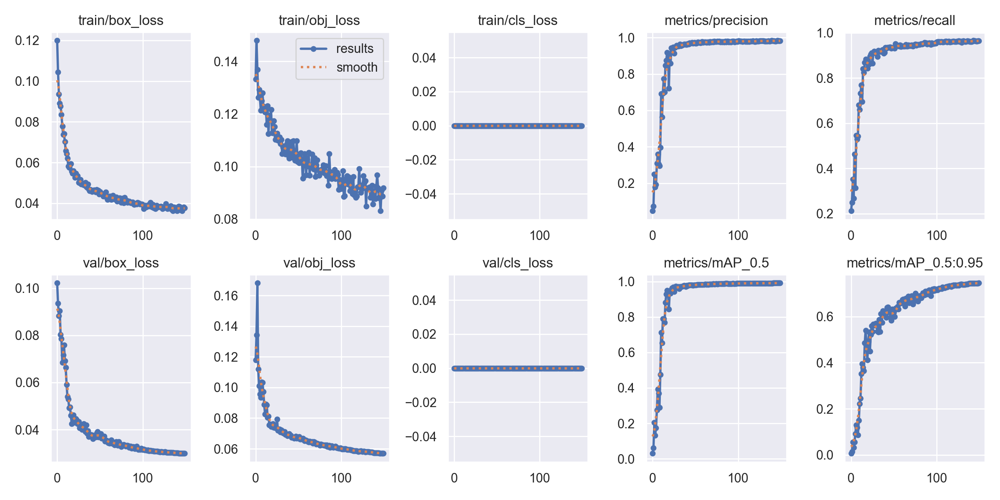


2. Kurva Precision-Recall:


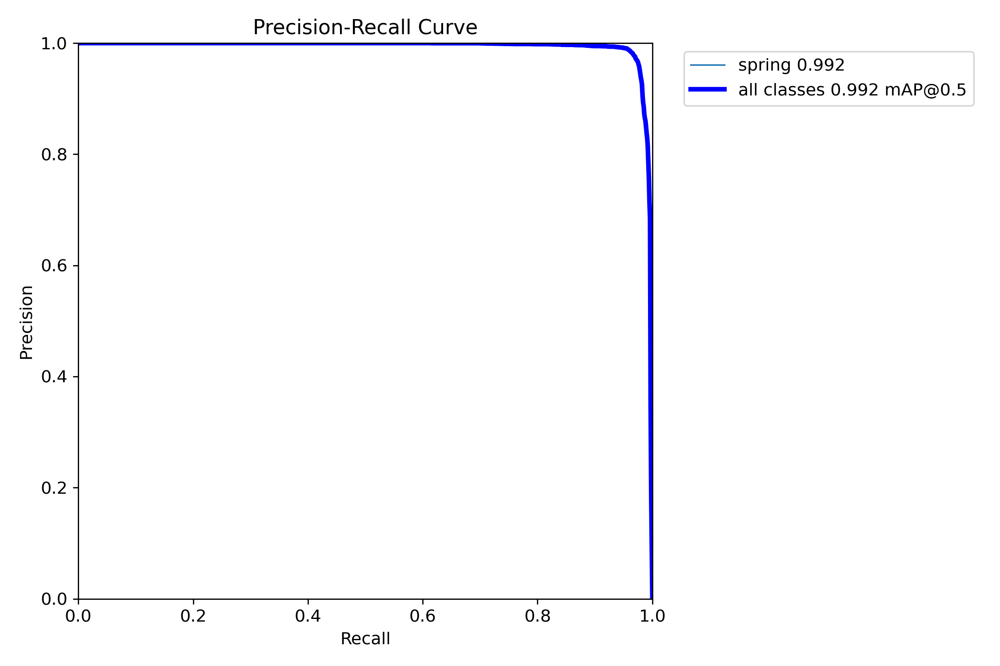


3. Matriks Konfusi (Confusion Matrix):


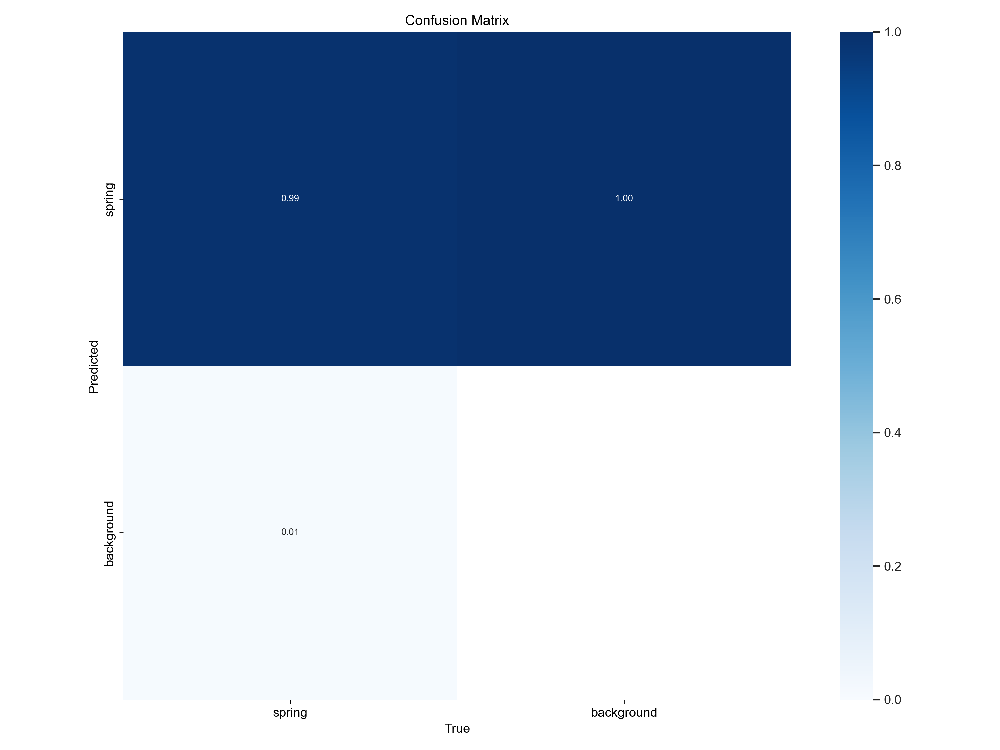

In [ ]:
from IPython.display import Image, display
import os

print("\n📊 VISUALISASI HASIL PELATIHAN SKENARIO 1 (YOLOv5s Tanpa CLAHE)")
print("-" * 60)

# Lokasi folder hasil training Skenario 1
res_dir_sc1 = '/content/yolov5/runs/train/YOLOv5s_Original_PeerSpring4'

# Menampilkan Grafik Loss & mAP
if os.path.exists(f'{res_dir_sc1}/results.png'):
    print("\n1. Grafik Metrik Pelatihan (Results.png):")
    display(Image(filename=f'{res_dir_sc1}/results.png', width=800))
else:
    print("❌ File results.png tidak ditemukan.")

# Menampilkan Precision-Recall Curve
if os.path.exists(f'{res_dir_sc1}/PR_curve.png'):
    print("\n2. Kurva Precision-Recall:")
    display(Image(filename=f'{res_dir_sc1}/PR_curve.png', width=600))
else:
     print("❌ File PR_curve.png tidak ditemukan.")

# Menampilkan Confusion Matrix
if os.path.exists(f'{res_dir_sc1}/confusion_matrix.png'):
    print("\n3. Matriks Konfusi (Confusion Matrix):")
    display(Image(filename=f'{res_dir_sc1}/confusion_matrix.png', width=600))
else:
     print("❌ File confusion_matrix.png tidak ditemukan.")

In [ ]:
# Mengekspor best.pt Skenario 1 menjadi ONNX
%cd /content/yolov5

!python export.py \
  --weights /content/yolov5/runs/train/YOLOv5s_Original_PeerSpring4/weights/best.pt \
  --include onnx \
  --simplify \
  --imgsz 640

print("\n✅ Ekspor Skenario 1 ke ONNX Selesai!")

/content/yolov5
export: data=data/coco128.yaml, weights=['/content/yolov5/runs/train/YOLOv5s_Original_PeerSpring4/weights/best.pt'], imgsz=[640], batch_size=1, device=cpu, half=False, inplace=False, keras=False, optimize=False, int8=False, per_tensor=False, dynamic=False, cache=, simplify=True, mlmodel=False, opset=17, verbose=False, workspace=4, nms=False, agnostic_nms=False, topk_per_class=100, topk_all=100, iou_thres=0.45, conf_thres=0.25, include=['onnx']
YOLOv5 🚀 v7.0-552-g35b48237 Python-3.13.15 torch-2.11.0+cu128 CPU

Fusing layers... 
Model summary: 68 layers, 7,012,822 parameters, 0 gradients, 15.8 GFLOPs

PyTorch: starting from /content/yolov5/runs/train/YOLOv5s_Original_PeerSpring4/weights/best.pt with output shape (1, 25200, 6) (13.8 MB)
requirements: Ultralytics requirement ['onnx>=1.12.0'] not found, attempting AutoUpdate...
Using Python 3.13.15 environment at: /usr
Resolved 5 packages in 309ms
Prepared 1 package in 588ms
Installed 1 package in 246ms
 + onnx==1.22.0

requ

# Skenario 2 | YOLOv5s + CLAHE

#5 Pelatihan YOLOv5 yang diterapkan CLAHE pada saluran L* a* b*

## 5.2 Implementasi Akuisisi dan Penyiapan Dataset
Tahapan ini berfungsi untuk mengunduh dataset secara otomatis dari API Roboflow langsung ke dalam sistem penyimpanan lokal komputasi awan (Google Colab). Format yang diunduh secara spesifik disesuaikan untuk arsitektur YOLOv5 PyTorch.

## Import Dataset from Roboflow

In [ ]:
# Instalasi pustaka antarmuka Roboflow secara senyap (quiet mode)
!pip install -q roboflow

In [ ]:
import os
from roboflow import Roboflow

print("📥 Memulai proses pengunduhan dataset dari Roboflow Workspace...")

# Otentikasi menggunakan API Key Nadhif
rf = Roboflow(api_key="mqzu0AtL172Rw5BZNWr3")
project = rf.workspace("nadhifs-workspace").project("datasetskripsi-g9pqj")
dataset = project.version(1).download("yolov5")

# Menyimpan variabel lokasi dataset untuk pemrosesan selanjutnya
dataset_path = dataset.location

print(f"\n✅ Dataset berhasil diunduh dan diekstrak secara otomatis pada direktori: {dataset_path}")

# Memverifikasi struktur folder yang dihasilkan oleh Roboflow
print("\n📂 Memverifikasi Struktur Direktori Dataset:")
!ls {dataset_path}

📥 Memulai proses pengunduhan dataset dari Roboflow Workspace...
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to DatasetSkripsi-1 in yolov5pytorch:: 100%|██████████| 607/607 [00:00<00:00, 9112.77it/s]



✅ Dataset berhasil diunduh dan diekstrak secara otomatis pada direktori: /content/yolov5/DatasetSkripsi-1

📂 Memverifikasi Struktur Direktori Dataset:
data.yaml  README.dataset.txt  README.roboflow.txt  train


## 5.3 Implementasi Prapemrosesan Citra (Komparasi HSV vs L*a*b*)

### 5.3.1 Skenario ini membuktikan hipotesis kegagalan konversi HSV pada citra dengan pantulan spekular ekstrem (glare) dibandingkan dengan ketahanan metode usulan CIE L*a*b* (L*L*L*).

### **Eksplorasi Visual Awal: Rekonstruksi HSV (RGB) vs Isolasi Saluran CIE L\*a\*b\* ($\text{L}^*\text{L}^*\text{L}^*$)**
Tahap eksplorasi awal ini merepresentasikan visualisasi pada **Gambar 5.1** di naskah skripsi, yang membandingkan:
1. **Citra BGR Asli (*Glare*)**
2. **CLAHE pada Saluran V (HSV) yang digabungkan kembali dengan saluran H dan S menuju RGB (`COLOR_HSV2RGB`)** — untuk mendemonstrasikan munculnya distorsi kromatik apabila informasi warna dipertahankan.
3. **CLAHE pada Saluran L\* (CIE L\*a\*b\*) yang direplikasi menjadi 3 saluran (`[L*, L*, L*]`)** — metode usulan yang mengeliminasi bias warna latar belakang.

/content
📥 Mengunduh 3 Citra Uji Statis (Glare Ekstrem) dari Google Drive...
✅ Download selesai!
🔍 Memproses Komparasi Ruang Warna pada 3 Sampel Citra Glare...



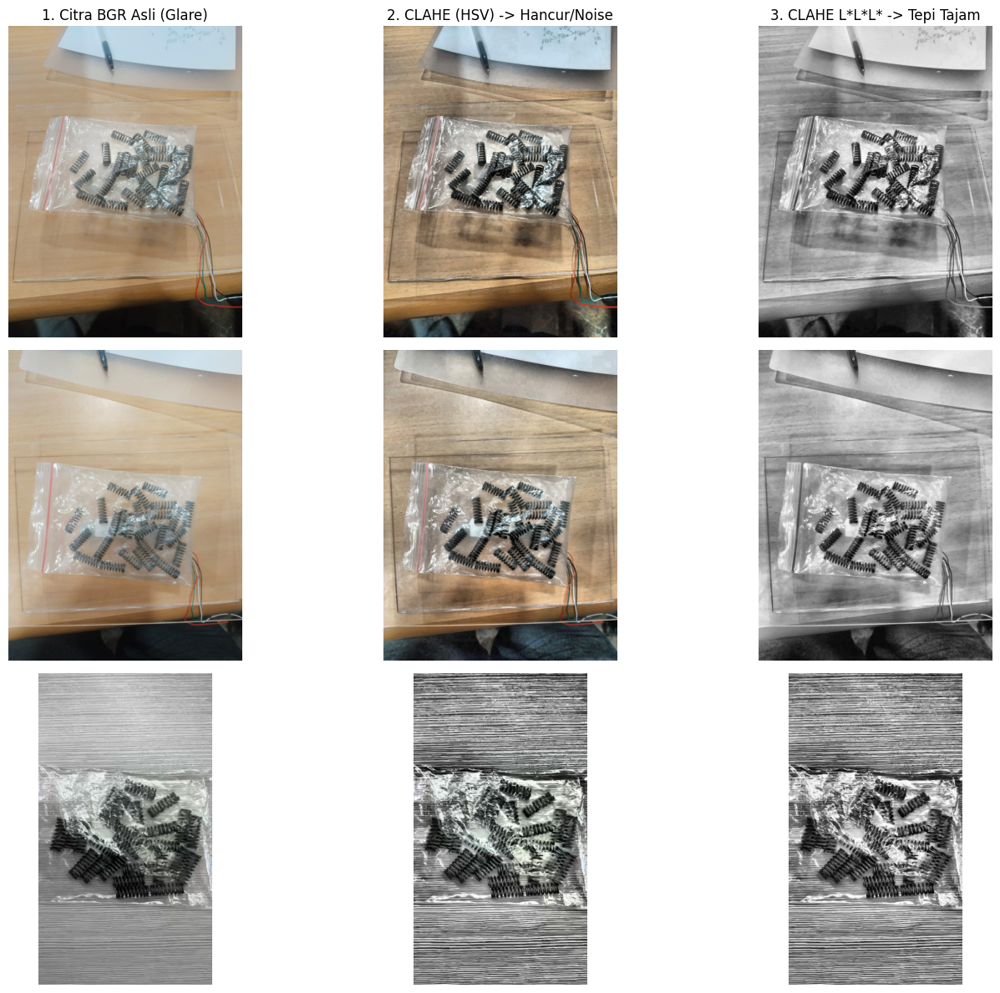

In [ ]:
%cd /content/
import os
import cv2
import matplotlib.pyplot as plt

# 1. Bikin folder test_images jika belum ada
os.makedirs('test_images', exist_ok=True)

print("📥 Mengunduh 3 Citra Uji Statis (Glare Ekstrem) dari Google Drive...")

# 2. Download menggunakan URL format baru agar terhindar dari error gdown
!gdown "https://drive.google.com/uc?id=1veo6hQc6Aqm3usB3gslPOwr2S_teqdOw" -O test_images/glare1.jpg -q
!gdown "https://drive.google.com/uc?id=1GPwBHwYm7PtYkdHMvEX2vQlGvqBdMCQA" -O test_images/glare2.jpg -q
!gdown "https://drive.google.com/uc?id=1RxywzPG7wDWqTRyDUjPRyIrbfPK4wQpM" -O test_images/glare3.jpg -q

print("✅ Download selesai!")
print("🔍 Memproses Komparasi Ruang Warna pada 3 Sampel Citra Glare...\n")

sample_images = ['glare1.jpg', 'glare2.jpg', 'glare3.jpg']
plt.figure(figsize=(15, 12))

for i, img_name in enumerate(sample_images):
    img_path = f'test_images/{img_name}'
    img_bgr = cv2.imread(img_path)

    if img_bgr is not None:
        # --- 1. Skenario HSV ---
        img_hsv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)
        h, s, v = cv2.split(img_hsv)
        clahe_hsv = cv2.createCLAHE(clipLimit=4.0, tileGridSize=(8, 8))
        v_clahe = clahe_hsv.apply(v)
        hsv_result = cv2.cvtColor(cv2.merge((h, s, v_clahe)), cv2.COLOR_HSV2RGB)

        # --- 2. Skenario LAB ---
        img_lab = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB)
        l, a, b = cv2.split(img_lab)
        clahe_lab = cv2.createCLAHE(clipLimit=4.0, tileGridSize=(8, 8))
        l_clahe = clahe_lab.apply(l)
        lab_result = cv2.merge((l_clahe, l_clahe, l_clahe))

        # --- PLOTTING GAMBAR ---
        plt.subplot(3, 3, i*3 + 1)
        if i == 0: plt.title("1. Citra BGR Asli (Glare)")
        plt.imshow(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB))
        plt.axis('off')

        plt.subplot(3, 3, i*3 + 2)
        if i == 0: plt.title("2. CLAHE (HSV) -> Hancur/Noise")
        plt.imshow(hsv_result)
        plt.axis('off')

        plt.subplot(3, 3, i*3 + 3)
        if i == 0: plt.title("3. CLAHE L*L*L* -> Tepi Tajam")
        plt.imshow(lab_result, cmap='gray')
        plt.axis('off')
    else:
        print(f"❌ Error: Gambar {img_name} tidak ditemukan/gagal dimuat!")

plt.tight_layout()
plt.show()

### 5.3.2 Eksplorasi Ruang Warna & Pelatihan Skenario 2 (Metode Usulan CLAHE CIE L\*a\*b\*)

#### **Implementasi Prapemrosesan Citra & Komparasi Setara (*Apples-to-Apples*) HSV vs CIE L\*a\*b\***
Sebelum mengeksekusi pelatihan model pada Skenario 2, dilakukan evaluasi kualitatif secara adil (*apples-to-apples*) antara ruang warna **HSV** (*Hue, Saturation, Value*) dan **CIE L\*a\*b\*** menggunakan parameter CLAHE *default training* (`clipLimit=4.0`, `tileGridSize=(8,8)`).

Untuk menjamin objektivitas ilmiah dan menghindari bias perbandingan visual, pengujian dieksekusi melalui dua skema yang setara:
1. **Skema Rekonstruksi Ruang Warna Penuh (Kembali ke RGB):** Saluran luminansi hasil CLAHE (`V_clahe` dan `L*_clahe`) digabungkan kembali dengan saluran kromatik aslinya (`H, S` pada HSV serta `a*, b*` pada CIE L\*a\*b\*), kemudian dikonversi kembali menuju ruang warna RGB (`COLOR_HSV2RGB` dan `COLOR_LAB2RGB`). Skema ini bertujuan mengamati dampak distorsi warna (*chromatic artifact*) apabila informasi warna dipertahankan.
2. **Skema Isolasi & Replikasi Saluran Luminansi (`[V, V, V]` vs `[L*, L*, L*]` Tanpa Konversi ke RGB):** Saluran kromatik (`H, S` maupun `a*, b*`) dieliminasi sepenuhnya. Saluran `V_clahe` dan `L*_clahe` masing-masing direplikasi menjadi 3 saluran identik (`[V, V, V]` dan `[L*, L*, L*]`) agar memenuhi syarat dimensi tensor masukan jaringan saraf (`[3, H, W]`). Skema ini membandingkan kemampuan murni kedua ruang warna dalam merestorasi ketajaman tepi (*edges*) komponen *peer spring* di tengah gangguan *glare*.

/content
📥 Mengunduh 3 Citra Sampel (Glare) dari Google Drive...
✅ Pengunduhan selesai!
🔍 Memproses Komparasi Setara (Apples-to-Apples) HSV vs CIE L*a*b*...

📊 1. KOMPARASI REKONSTRUKSI RUANG WARNA PENUH (DIKONVERSI KEMBALI KE RGB)


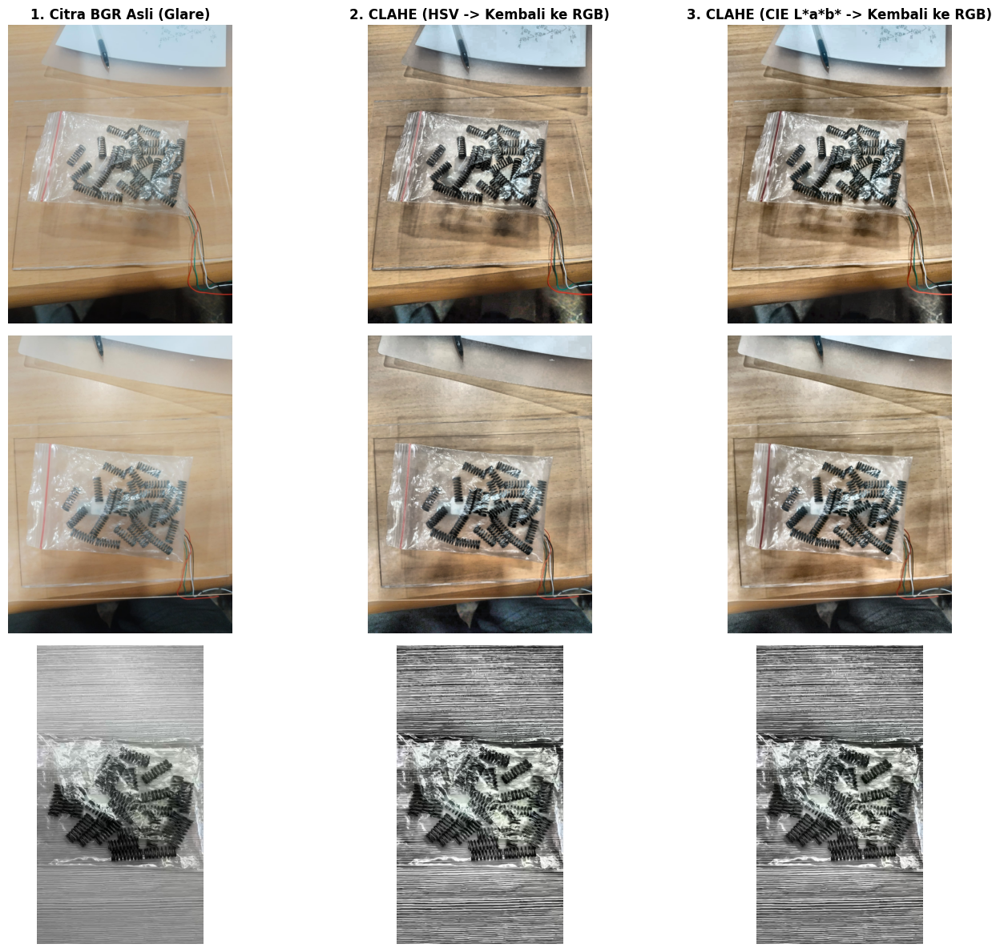


📊 2. KOMPARASI ISOLASI & REPLIKASI 3 SALURAN ([V, V, V] vs [L*, L*, L*] TANPA KONVERSI RGB)


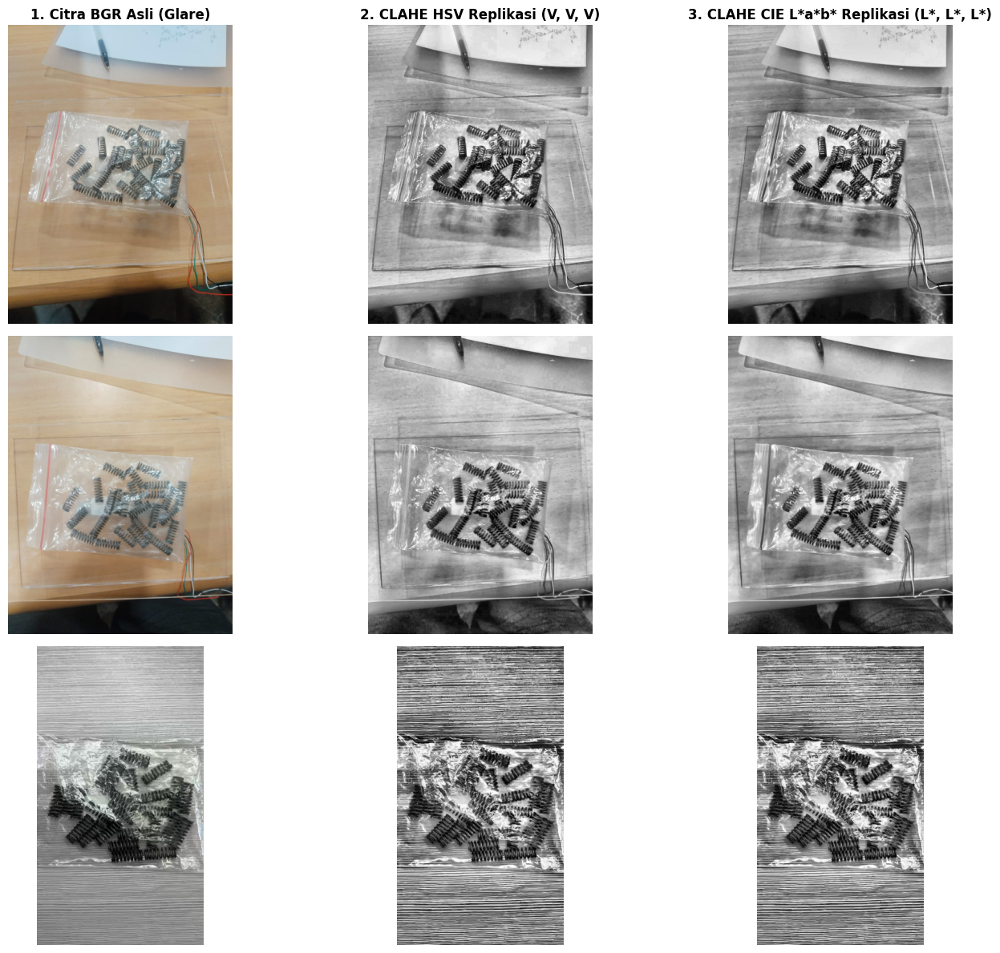

In [ ]:
%cd /content/
import os
import cv2
import matplotlib.pyplot as plt

# 1. Membuat direktori penyimpanan sampel citra uji eksplorasi ruang warna
os.makedirs('test_images', exist_ok=True)
print("📥 Mengunduh 3 Citra Sampel (Glare) dari Google Drive...")

# 2. Mengunduh 3 citra sampel menggunakan tautan Google Drive yang telah dikoreksi (case-sensitive)
!gdown --fuzzy "https://drive.google.com/file/d/1veo6hQc6Aqm3usB3gslPOwr2S_teqdOw/view?usp=drive_link" -O test_images/glare1.jpg -q
!gdown --fuzzy "https://drive.google.com/file/d/1GPwBHwYm7PtYkdHMvEX2vQlGvqBdMCQA/view?usp=sharing" -O test_images/glare2.jpg -q
!gdown --fuzzy "https://drive.google.com/file/d/1RxywzPG7wDWqTRyDUjPRyIrbfPK4wQpM/view?usp=drive_link" -O test_images/glare3.jpg -q

print("✅ Pengunduhan selesai!")
print("🔍 Memproses Komparasi Setara (Apples-to-Apples) HSV vs CIE L*a*b*...\n")

sample_images = ['glare1.jpg', 'glare2.jpg', 'glare3.jpg']
clahe_op = cv2.createCLAHE(clipLimit=4.0, tileGridSize=(8, 8))

# ==============================================================================
# BAGIAN A: KOMPARASI REKONSTRUKSI WARNA PENUH (KEMBALI KE RGB)
# Membandingkan: (1) Citra Asli vs (2) HSV->RGB vs (3) CIE L*a*b*->RGB
# ==============================================================================
print("📊 1. KOMPARASI REKONSTRUKSI RUANG WARNA PENUH (DIKONVERSI KEMBALI KE RGB)")
plt.figure(figsize=(15, 12))

for i, img_name in enumerate(sample_images):
    img_bgr = cv2.imread(f'test_images/{img_name}')
    if img_bgr is not None:
        img_rgb_ori = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

        # --- HSV: CLAHE pada V -> Merge (H, S, V_clahe) -> Konversi ke RGB ---
        img_hsv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)
        h, s, v = cv2.split(img_hsv)
        v_clahe = clahe_op.apply(v)
        hsv_to_rgb = cv2.cvtColor(cv2.merge((h, s, v_clahe)), cv2.COLOR_HSV2RGB)

        # --- CIE L*a*b*: CLAHE pada L* -> Merge (L*_clahe, a*, b*) -> Konversi ke RGB ---
        img_lab = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB)
        l, a, b = cv2.split(img_lab)
        l_clahe = clahe_op.apply(l)
        lab_to_rgb = cv2.cvtColor(cv2.merge((l_clahe, a, b)), cv2.COLOR_LAB2RGB)

        # Plotting Bagian A (3 Kolom Berwarna)
        plt.subplot(3, 3, i*3 + 1)
        if i == 0: plt.title("1. Citra BGR Asli (Glare)", fontsize=12, fontweight='bold')
        plt.imshow(img_rgb_ori)
        plt.axis('off')

        plt.subplot(3, 3, i*3 + 2)
        if i == 0: plt.title("2. CLAHE (HSV -> Kembali ke RGB)", fontsize=12, fontweight='bold')
        plt.imshow(hsv_to_rgb)
        plt.axis('off')

        plt.subplot(3, 3, i*3 + 3)
        if i == 0: plt.title("3. CLAHE (CIE L*a*b* -> Kembali ke RGB)", fontsize=12, fontweight='bold')
        plt.imshow(lab_to_rgb)
        plt.axis('off')

plt.tight_layout()
plt.show()

# ==============================================================================
# BAGIAN B: KOMPARASI REPLIKASI SALURAN LUMINANSI (TANPA KONVERSI KE RGB)
# Membandingkan: (1) Citra Asli vs (2) Tensor [V, V, V] vs (3) Tensor [L*, L*, L*]
# ==============================================================================
print("\n📊 2. KOMPARASI ISOLASI & REPLIKASI 3 SALURAN ([V, V, V] vs [L*, L*, L*] TANPA KONVERSI RGB)")
plt.figure(figsize=(15, 12))

for i, img_name in enumerate(sample_images):
    img_bgr = cv2.imread(f'test_images/{img_name}')
    if img_bgr is not None:
        img_rgb_ori = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

        # --- HSV: CLAHE pada V -> Replikasi 3 Saluran (V, V, V) Tanpa Konversi RGB ---
        img_hsv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)
        h, s, v = cv2.split(img_hsv)
        v_clahe = clahe_op.apply(v)
        vvv_tensor = cv2.merge((v_clahe, v_clahe, v_clahe))

        # --- CIE L*a*b*: CLAHE pada L* -> Replikasi 3 Saluran (L*, L*, L*) Tanpa Konversi RGB ---
        img_lab = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB)
        l, a, b = cv2.split(img_lab)
        l_clahe = clahe_op.apply(l)
        lll_tensor = cv2.merge((l_clahe, l_clahe, l_clahe))

        # Plotting Bagian B (Apples-to-Apples Grayscale Tensor)
        plt.subplot(3, 3, i*3 + 1)
        if i == 0: plt.title("1. Citra BGR Asli (Glare)", fontsize=12, fontweight='bold')
        plt.imshow(img_rgb_ori)
        plt.axis('off')

        plt.subplot(3, 3, i*3 + 2)
        if i == 0: plt.title("2. CLAHE HSV Replikasi (V, V, V)", fontsize=12, fontweight='bold')
        plt.imshow(vvv_tensor)
        plt.axis('off')

        plt.subplot(3, 3, i*3 + 3)
        if i == 0: plt.title("3. CLAHE CIE L*a*b* Replikasi (L*, L*, L*)", fontsize=12, fontweight='bold')
        plt.imshow(lll_tensor)
        plt.axis('off')

plt.tight_layout()
plt.show()

## 5.4 Implementasi Pelatihan Model Pendeteksian Objek
Mengonversi seluruh dataset latih ke format tensor L* L* L* secara batching, kemudian memulai pelatihan YOLOv5s.

In [ ]:
import os
import glob
import cv2
import yaml
import shutil
from tqdm import tqdm

# 1. KEMBALI KE ROOT COLAB
%cd /content/

# Nama folder dari output Roboflow Anda
dataset_dir = "/content/DatasetSkripsi-1"

# ==========================================
# 2. BATCHING CLAHE KE SELURUH DATASET
# ==========================================
print(f"\n🚀 1. Memulai Konversi BATCH CLAHE pada seluruh Dataset di {dataset_dir}...")
if os.path.exists(dataset_dir):
    for split in ['train', 'valid', 'test']:
        img_dir = f"{dataset_dir}/{split}/images"
        if not os.path.exists(img_dir):
            continue

        image_paths = glob.glob(f"{img_dir}/*.jpg")

        for img_path in tqdm(image_paths, desc=f"Memproses folder '{split}'"):
            img_bgr = cv2.imread(img_path)
            if img_bgr is not None:
                img_lab = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB)
                l_channel, _, _ = cv2.split(img_lab)
                clahe = cv2.createCLAHE(clipLimit=4.0, tileGridSize=(8, 8))
                cl = clahe.apply(l_channel)
                l_merged = cv2.merge((cl, cl, cl))
                cv2.imwrite(img_path, l_merged)
    print("✅ Konversi BATCH L*L*L* selesai!")
else:
    print(f"❌ Error: Direktori {dataset_dir} tidak ditemukan.")

# ==========================================
# 3. MEMPERBAIKI DATA.YAML (TRIK CAPSTONE)
# ==========================================
print("\n⚙️ 2. Memperbaiki file data.yaml agar YOLO tidak error...")
yaml_path = f"{dataset_dir}/data.yaml"

if os.path.exists(yaml_path):
    with open(yaml_path, 'r') as f:
        yaml_config = yaml.safe_load(f)

    # Memaksa YOLO menggunakan folder 'train' sebagai folder validasi ('val')
    yaml_config['train'] = f"{dataset_dir}/train/images"
    yaml_config['val'] = f"{dataset_dir}/train/images"

    # Hapus konfigurasi test jika ada, agar tidak membingungkan YOLO
    if 'test' in yaml_config:
        del yaml_config['test']

    with open(yaml_path, 'w') as f:
        yaml.dump(yaml_config, f)
    print("✅ File data.yaml berhasil di-patch! Parameter 'val' sudah mengarah ke 'train/images'.")
else:
    print(f"❌ Error: File {yaml_path} tidak ditemukan!")

# ==========================================
# 4. PELATIHAN YOLOV5s (TRAINING)
# ==========================================
print("\n🔥 3. Memulai Pelatihan Jaringan YOLOv5s (150 Epochs)...")

# Memastikan kita berada di dalam folder yolov5
if not os.path.exists('/content/yolov5'):
    !git clone https://github.com/ultralytics/yolov5
%cd /content/yolov5
!pip install -qr requirements.txt

# Eksekusi Pelatihan
!python train.py \
  --img 640 \
  --batch 16 \
  --epochs 150 \
  --data {dataset_dir}/data.yaml \
  --weights yolov5s.pt \
  --name YOLOv5s_CLAHE_PeerSpring \
  --cache

/content

🚀 1. Memulai Konversi BATCH CLAHE pada seluruh Dataset di /content/DatasetSkripsi-1...


Memproses folder 'train': 100%|██████████| 302/302 [00:02<00:00, 136.23it/s]


✅ Konversi BATCH L*L*L* selesai!

⚙️ 2. Memperbaiki file data.yaml agar YOLO tidak error...
✅ File data.yaml berhasil di-patch! Parameter 'val' sudah mengarah ke 'train/images'.

🔥 3. Memulai Pelatihan Jaringan YOLOv5s (150 Epochs)...
Cloning into 'yolov5'...
remote: Enumerating objects: 18752, done.
remote: Counting objects: 100% (327/327), done.
remote: Compressing objects: 100% (191/191), done.
remote: Total 18752 (delta 268), reused 136 (delta 136), pack-reused 18425 (from 4)
Receiving objects: 100% (18752/18752), 17.75 MiB | 23.70 MiB/s, done.
Resolving deltas: 100% (12761/12761), done.
/content/yolov5
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.4/46.4 kB 3.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 33.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 75.4/75.4 kB 8.3 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update

In [ ]:
# Pindah ke direktori yolov5
%cd /content/yolov5

# Instal pustaka ONNX dan ONNX Simplifier
!pip install -q onnx onnxsim

# Eksekusi skrip export dari YOLOv5
!python export.py \
  --weights /content/yolov5/runs/train/YOLOv5s_CLAHE_PeerSpring/weights/best.pt \
  --include onnx \
  --simplify

/content/yolov5
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 19.1/19.1 MB 87.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 71.0 MB/s eta 0:00:00
export: data=data/coco128.yaml, weights=['/content/yolov5/runs/train/YOLOv5s_CLAHE_PeerSpring/weights/best.pt'], imgsz=[640, 640], batch_size=1, device=cpu, half=False, inplace=False, keras=False, optimize=False, int8=False, per_tensor=False, dynamic=False, cache=, simplify=True, mlmodel=False, opset=17, verbose=False, workspace=4, nms=False, agnostic_nms=False, topk_per_class=100, topk_all=100, iou_thres=0.45, conf_thres=0.25, include=['onnx']
YOLOv5 🚀 v7.0-552-g35b48237 Python-3.13.15 torch-2.11.0+cu128 CPU

Fusing layers... 
Model summary: 68 layers, 7,012,822 parameters, 0 gradients, 15.8 GFLOPs

PyTorch: starting from /content/yolov5/runs/train/YOLOv5s_CLAHE_PeerSpring/weights/best.pt with output shape (1, 25200, 6) (13.8 MB)

ONNX: starting export with onnx 1.22.0...
requirements: Ultralytics requirements ['onn

## 5.5 Pengujian Grid Search Parameter CLAHE
Mengeksekusi pencarian parameter terbaik (*Grid Search*) untuk algoritme CLAHE (*Contrast Limited Adaptive Histogram Equalization*) pada ruang warna L*a*b*. Pengujian dilakukan menggunakan model `best.pt` terhadap 10 citra uji statis yang memiliki pantulan spekular (*glare*) ekstrem. Tujuannya adalah mengidentifikasi kombinasi *Clip Limit* dan *Grid Size* yang menghasilkan deviasi (selisih) terkecil dari target aktual, yaitu 25 *peer spring*.

In [ ]:
import torch
import cv2
import glob
import pandas as pd
import numpy as np

print("🔍 Memulai Grid Search Parameter CLAHE pada 10 Citra Uji Glare Ekstrem...")

# 1. Load Model YOLOv5 yang baru saja dilatih
model = torch.hub.load('/content/yolov5', 'custom', path='/content/yolov5/runs/train/YOLOv5s_CLAHE_PeerSpring/weights/best.pt', source='local')
model.conf = 0.50 # Set Confidence Threshold 50%

# 2. Parameter yang akan dieksplorasi
clip_limits = [2.0, 3.0, 4.0]
grid_sizes = [(4, 4), (8, 8), (16, 16)]

# Load daftar gambar
test_images = glob.glob('/content/test_images/*.jpg')
TARGET_COUNT = 25
results = []

# 3. Looping Grid Search
for clip in clip_limits:
    for grid in grid_sizes:
        total_error = 0

        for img_path in test_images:
            img_bgr = cv2.imread(img_path)
            if img_bgr is None: continue

            # Proses CLAHE sesuai kombinasi parameter saat ini
            img_lab = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB)
            l, a, b = cv2.split(img_lab)
            clahe = cv2.createCLAHE(clipLimit=clip, tileGridSize=grid)
            l_clahe = clahe.apply(l)
            img_clahe = cv2.merge((l_clahe, l_clahe, l_clahe))

            # Inferensi YOLOv5
            pred = model(img_clahe)
            detected_count = len(pred.xyxy[0]) # Hitung jumlah bounding box

            # Hitung selisih dari target asli (25)
            error = abs(TARGET_COUNT - detected_count)
            total_error += error

        avg_error = total_error / len(test_images)
        results.append({
            'Clip Limit': clip,
            'Grid Size': f"{grid[0]}x{grid[1]}",
            'Avg Error (Selisih)': avg_error
        })

# 4. Tampilkan Hasil
df_results = pd.DataFrame(results)
print("\n🏆 HASIL GRID SEARCH (Diurutkan dari Error Terkecil/Terbaik):")
print(df_results.sort_values('Avg Error (Selisih)').to_string(index=False))

🔍 Memulai Grid Search Parameter CLAHE pada 10 Citra Uji Glare Ekstrem...
YOLOv5 🚀 v7.0-552-g35b48237 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)

Fusing layers... 
Model summary: 68 layers, 7,012,822 parameters, 0 gradients, 15.8 GFLOPs
Adding AutoShape... 

🏆 HASIL GRID SEARCH (Diurutkan dari Error Terkecil/Terbaik):
 Clip Limit Grid Size  Avg Error (Selisih)
        3.0       4x4             1.333333
        4.0       4x4             1.333333
        2.0     16x16             1.666667
        2.0       8x8             1.666667
        4.0       8x8             1.666667
        3.0       8x8             1.666667
        2.0       4x4             2.000000
        3.0     16x16             2.000000
        4.0     16x16             2.000000


### Evaluasi Grid Search - Parameter CLAHE


📊 Membikin Visualisasi Grafik Grid Search...




Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.



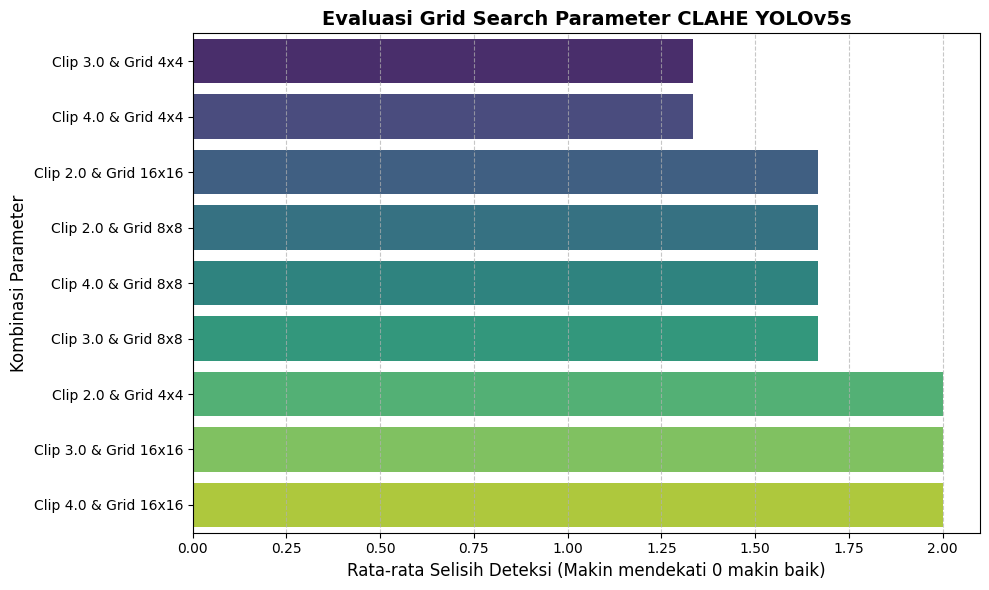

✅ Grafik berhasil disimpan sebagai 'Grid_Search_CLAHE_Result.png'. Jangan lupa di-download!


In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# 5. Visualisasi Grafik Bar untuk Hasil Grid Search
print("\n📊 Membikin Visualisasi Grafik Grid Search...")

# Membuat label kombinasi agar mudah dibaca di grafik
df_results['Kombinasi'] = 'Clip ' + df_results['Clip Limit'].astype(str) + ' & Grid ' + df_results['Grid Size']

# Mengurutkan data dari error terkecil ke terbesar
df_sorted = df_results.sort_values('Avg Error (Selisih)')

plt.figure(figsize=(10, 6))
sns.barplot(
    data=df_sorted,
    x='Avg Error (Selisih)',
    y='Kombinasi',
    palette='viridis' # Warna gradasi agar terlihat saintifik
)

plt.title('Evaluasi Grid Search Parameter CLAHE YOLOv5s', fontsize=14, fontweight='bold')
plt.xlabel('Rata-rata Selisih Deteksi (Makin mendekati 0 makin baik)', fontsize=12)
plt.ylabel('Kombinasi Parameter', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.7)

plt.tight_layout()
# Menyimpan gambar grafik dengan resolusi tinggi untuk skripsi
plt.savefig('/content/Grid_Search_CLAHE_Result.png', dpi=300)
plt.show()

print("✅ Grafik berhasil disimpan sebagai 'Grid_Search_CLAHE_Result.png'. Jangan lupa di-download!")

# Perbandingan Skenario 1 dan Skenario 2, serta perbandingan saluran HSV vs L* a* b*

## Komparasi Hasil Bounding Box - HSV vs L* a* b* | Menggunakan YOLOv5 Original

In [ ]:
import cv2
import os

print("Membuat gambar uji HSV dan LAB...")
os.makedirs('/content/test_hsv', exist_ok=True)
os.makedirs('/content/test_lab', exist_ok=True)

sample_images = ['glare1.jpg', 'glare2.jpg', 'glare3.jpg']

for img_name in sample_images:
    img_path = f'/content/test_images/{img_name}'
    img_bgr = cv2.imread(img_path)

    if img_bgr is not None:
        # --- Buat Gambar HSV ---
        img_hsv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)
        h, s, v = cv2.split(img_hsv)
        clahe_hsv = cv2.createCLAHE(clipLimit=3.0, tileGridSize=(4, 4))
        v_clahe = clahe_hsv.apply(v)
        img_hsv_infer = cv2.merge((v_clahe, v_clahe, v_clahe))
        cv2.imwrite(f'/content/test_hsv/{img_name}', img_hsv_infer)

        # --- Buat Gambar LAB ---
        img_lab = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB)
        l, a, b = cv2.split(img_lab)
        clahe_lab = cv2.createCLAHE(clipLimit=3.0, tileGridSize=(4, 4))
        l_clahe = clahe_lab.apply(l)
        img_lab_infer = cv2.merge((l_clahe, l_clahe, l_clahe))
        cv2.imwrite(f'/content/test_lab/{img_name}', img_lab_infer)

print("✅ Gambar uji HSV dan LAB berhasil dibuat!")

Membuat gambar uji HSV dan LAB...
✅ Gambar uji HSV dan LAB berhasil dibuat!


In [ ]:
%cd /content/yolov5

# Ganti angka pada YOLOv5s_Original_PeerSpring4 sesuai dengan folder runs Anda jika berbeda
# Deteksi gambar HSV
!python detect.py --weights /content/yolov5/runs/train/YOLOv5s_Original_PeerSpring4/weights/best.pt \
  --img 640 --conf 0.50 --source /content/test_hsv/ \
  --name detect_HSV --save-txt

# Deteksi gambar LAB
!python detect.py --weights /content/yolov5/runs/train/YOLOv5s_Original_PeerSpring4/weights/best.pt \
  --img 640 --conf 0.50 --source /content/test_lab/ \
  --name detect_LAB --save-txt

/content/yolov5
detect: weights=['/content/yolov5/runs/train/YOLOv5s_Original_PeerSpring4/weights/best.pt'], source=/content/test_hsv/, data=data/coco128.yaml, imgsz=[640, 640], conf_thres=0.5, iou_thres=0.45, max_det=1000, device=, view_img=False, save_txt=True, save_format=0, save_csv=False, save_conf=False, save_crop=False, nosave=False, classes=None, agnostic_nms=False, augment=False, update=False, project=runs/detect, name=detect_HSV, exist_ok=False, line_thickness=3, hide_labels=False, hide_conf=False, half=False, dnn=False, vid_stride=1
YOLOv5 🚀 v7.0-552-g35b48237 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)

Fusing layers... 
Model summary: 68 layers, 7,012,822 parameters, 0 gradients, 15.8 GFLOPs
image 1/3 /content/test_hsv/glare1.jpg: 640x480 23 springs, 31.2ms
image 2/3 /content/test_hsv/glare2.jpg: 640x480 24 springs, 33.0ms
image 3/3 /content/test_hsv/glare3.jpg: 640x384 21 springs, 33.0ms
Speed: 0.5ms pre-process, 32.4ms inference, 27.7ms NMS per image at


🔍 HASIL DETEKSI (HSV vs CIE L*a*b*)



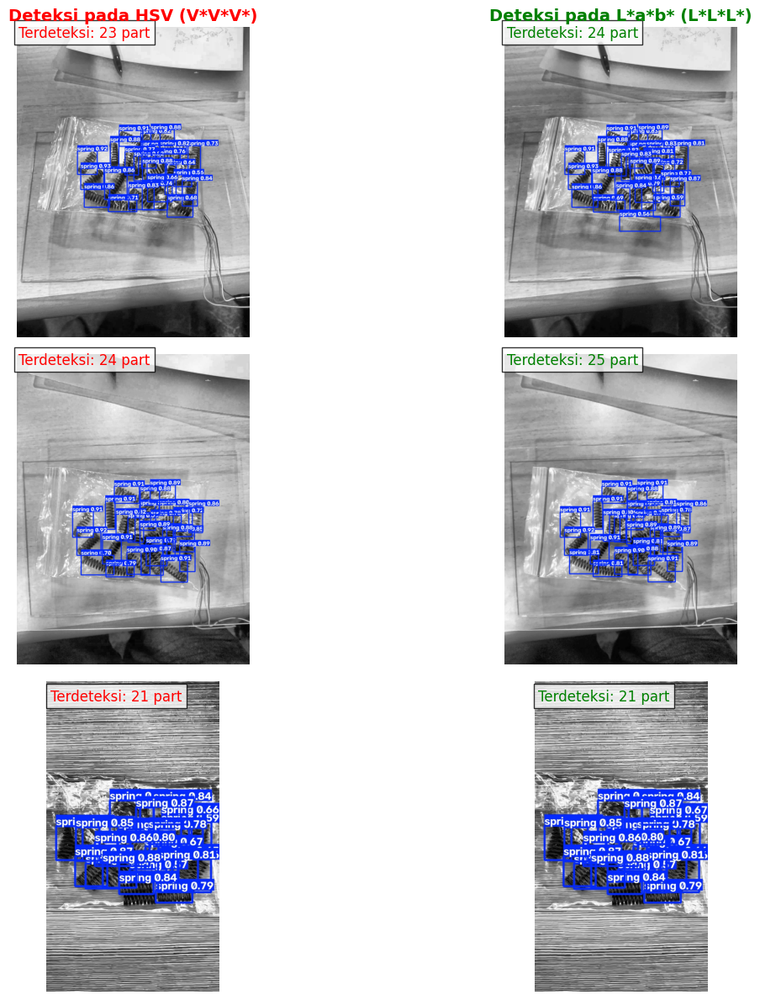

In [ ]:
import matplotlib.pyplot as plt
import cv2
import os

print("\n🔍 HASIL DETEKSI (HSV vs CIE L*a*b*)\n")
sample_images = ['glare1.jpg', 'glare2.jpg', 'glare3.jpg']
plt.figure(figsize=(15, 12))

for i, img_name in enumerate(sample_images):
    # Path gambar hasil deteksi
    hsv_res_path = f'/content/yolov5/runs/detect/detect_HSV/{img_name}'
    lab_res_path = f'/content/yolov5/runs/detect/detect_LAB/{img_name}'

    # Path text log deteksi (untuk menghitung jumlah kotak)
    hsv_txt_path = f'/content/yolov5/runs/detect/detect_HSV/labels/{img_name.replace(".jpg", ".txt")}'
    lab_txt_path = f'/content/yolov5/runs/detect/detect_LAB/labels/{img_name.replace(".jpg", ".txt")}'

    # Hitung jumlah deteksi HSV
    count_hsv = 0
    if os.path.exists(hsv_txt_path):
        with open(hsv_txt_path, 'r') as f:
            count_hsv = len(f.readlines())

    # Hitung jumlah deteksi LAB
    count_lab = 0
    if os.path.exists(lab_txt_path):
        with open(lab_txt_path, 'r') as f:
            count_lab = len(f.readlines())

    # Load gambar jika ada
    img_hsv = cv2.imread(hsv_res_path) if os.path.exists(hsv_res_path) else np.zeros((640,640,3), dtype=np.uint8)
    img_lab = cv2.imread(lab_res_path) if os.path.exists(lab_res_path) else np.zeros((640,640,3), dtype=np.uint8)

    # Plotting HSV
    plt.subplot(3, 2, i*2 + 1)
    if i == 0: plt.title("Deteksi pada HSV (V*V*V*)", fontsize=14, fontweight='bold', color='red')
    plt.imshow(cv2.cvtColor(img_hsv, cv2.COLOR_BGR2RGB))
    plt.axis('off')
    plt.text(10, 50, f'Terdeteksi: {count_hsv} part', color='red', fontsize=12, bbox=dict(facecolor='white', alpha=0.8))

    # Plotting LAB
    plt.subplot(3, 2, i*2 + 2)
    if i == 0: plt.title("Deteksi pada L*a*b* (L*L*L*)", fontsize=14, fontweight='bold', color='green')
    plt.imshow(cv2.cvtColor(img_lab, cv2.COLOR_BGR2RGB))
    plt.axis('off')
    plt.text(10, 50, f'Terdeteksi: {count_lab} part', color='green', fontsize=12, bbox=dict(facecolor='white', alpha=0.8))

plt.tight_layout()
plt.show()

## Komparasi Hasil Bounding Box - HSV vs L* a* b* | Menggunakan YOLOv5 + CLAHE | Data Tes Terbaru (Top View)

🧹 Membersihkan seluruh folder hasil lama...

📥 Menyiapkan Citra Uji Baru...
🔄 Konversi HSV dan LAB (Mengubah nama file untuk mencegah bentrok)...

🚀 Memulai Pengujian 4 Arah...

🔍 VISUALISASI HASIL



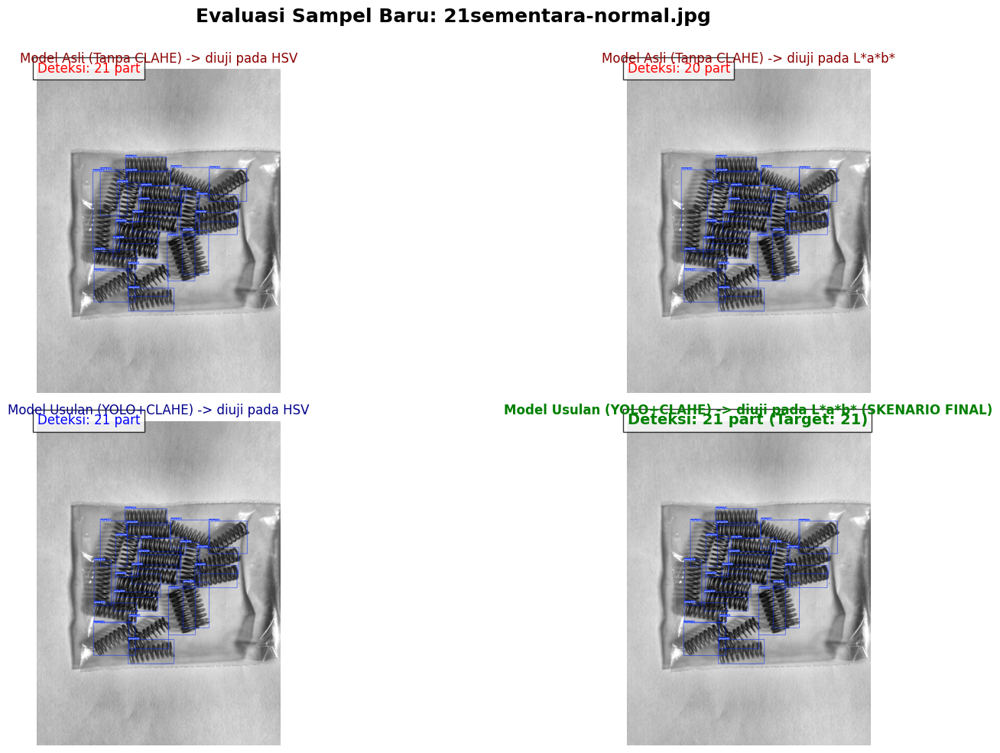

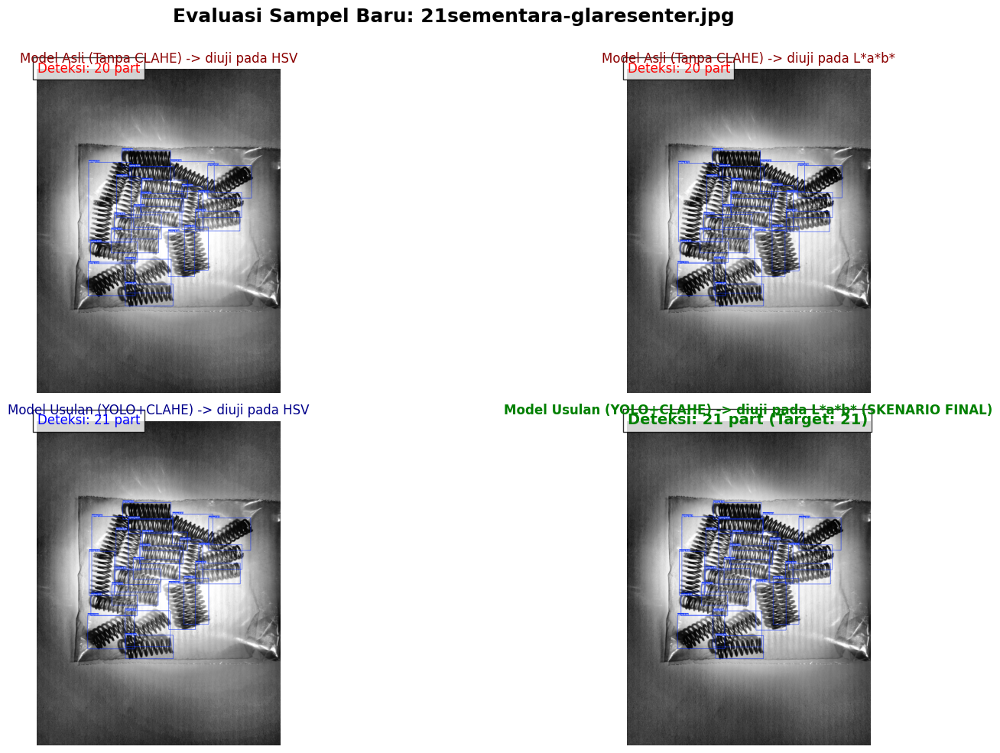

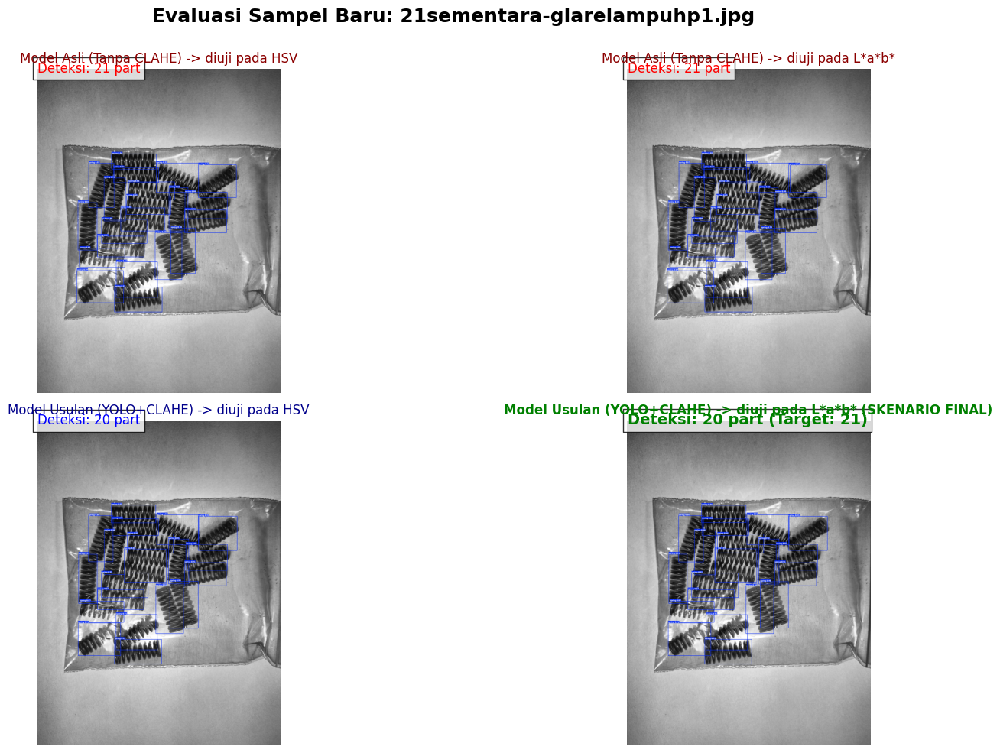

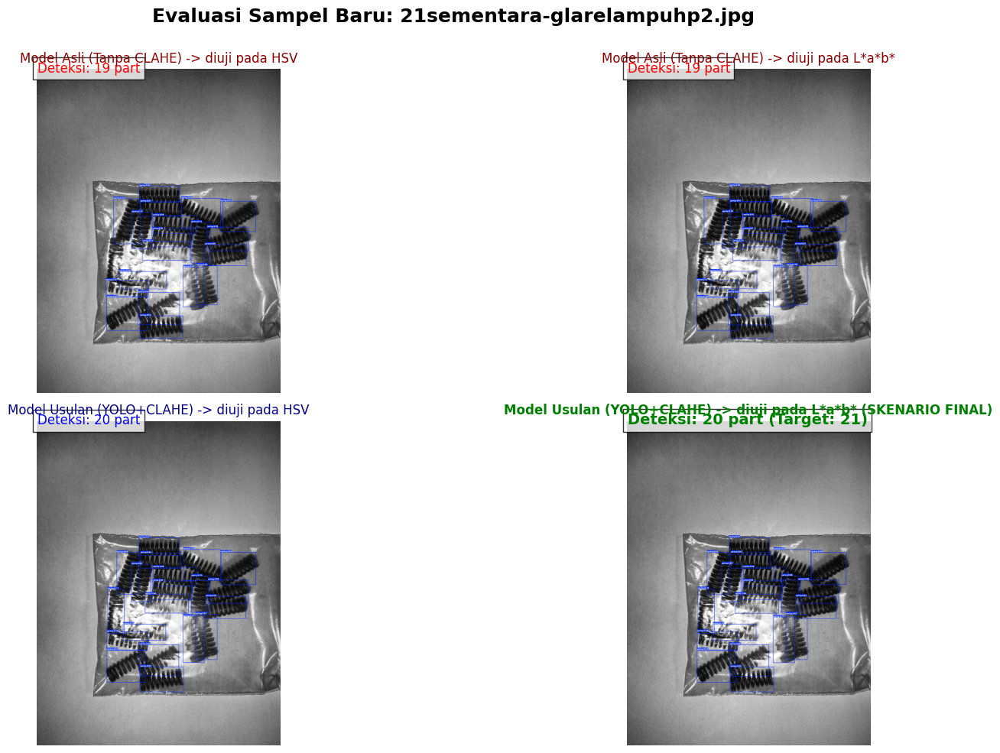

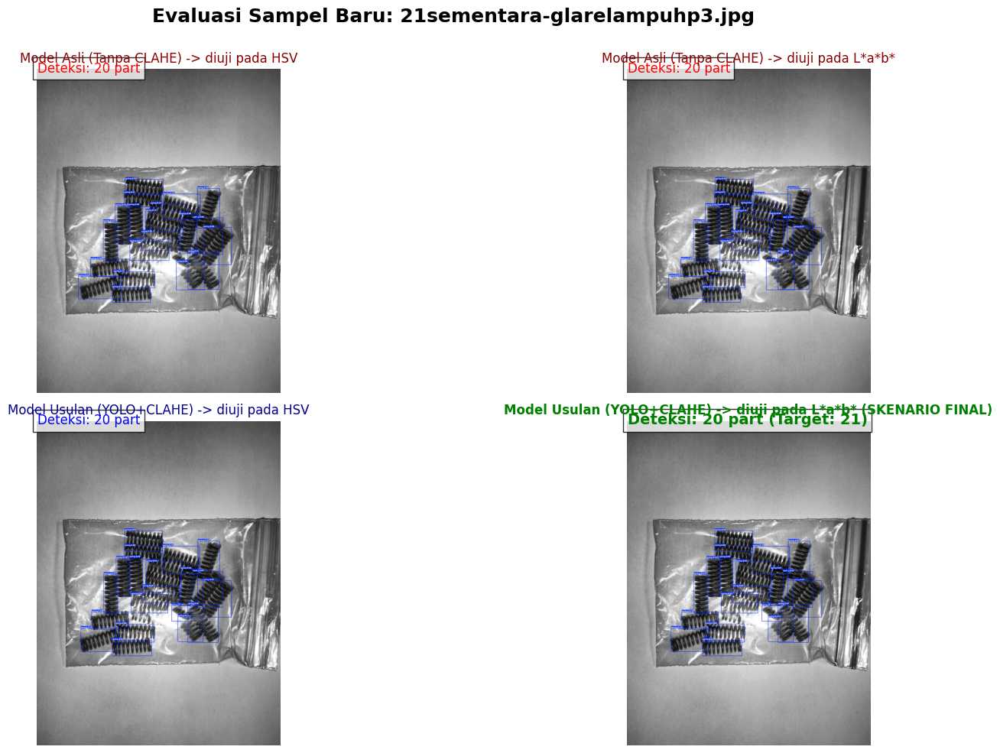

...

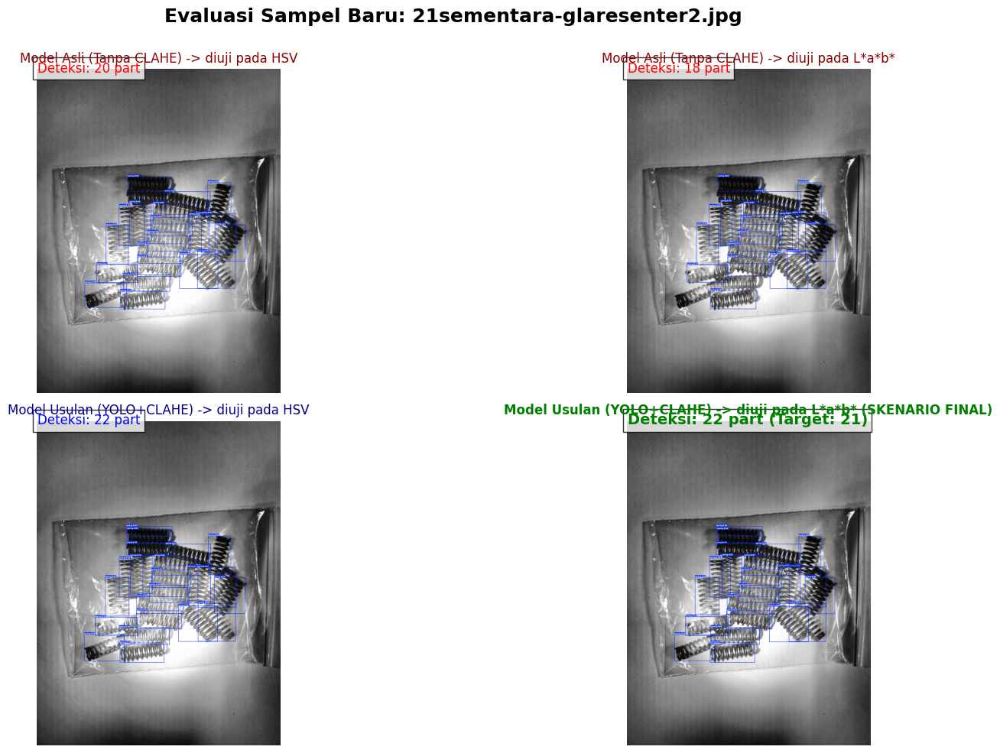

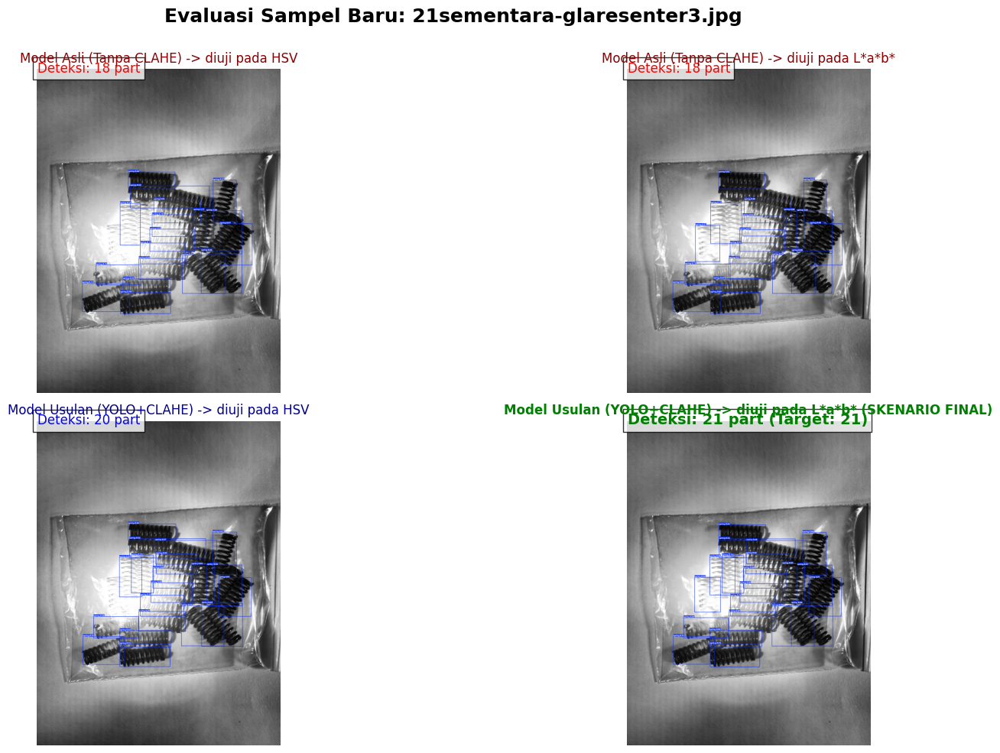

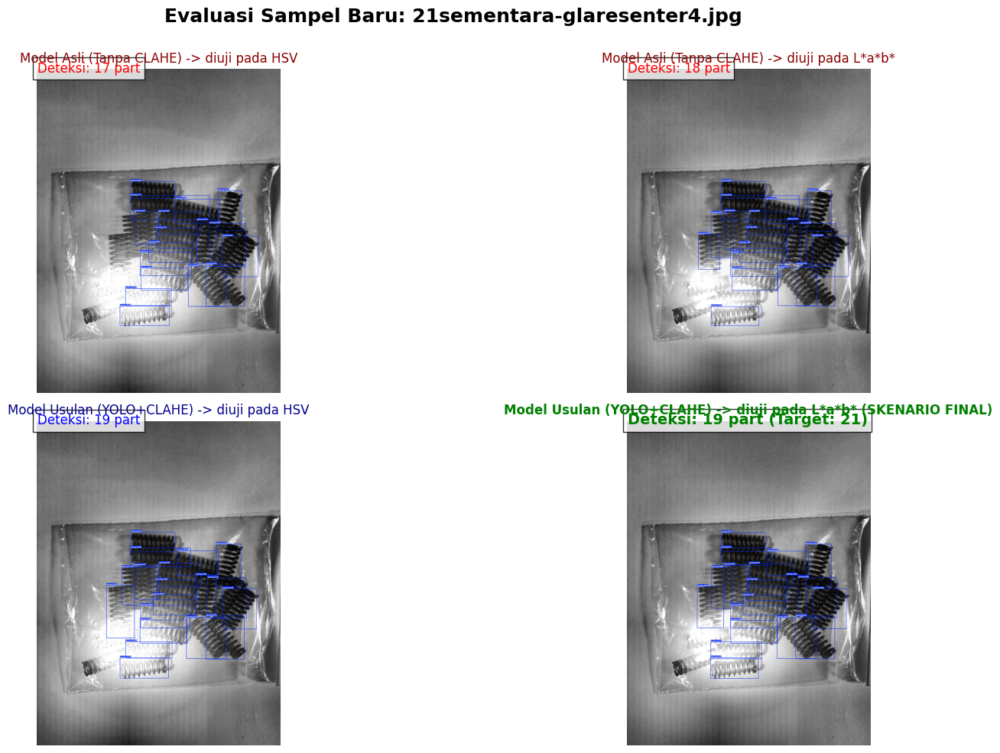

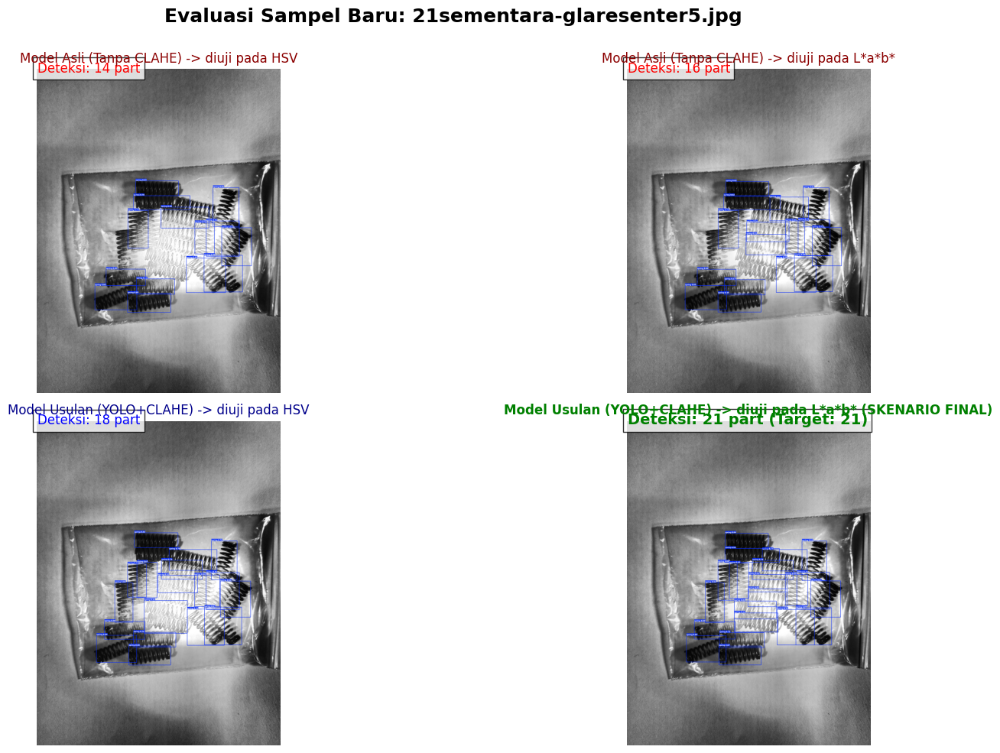

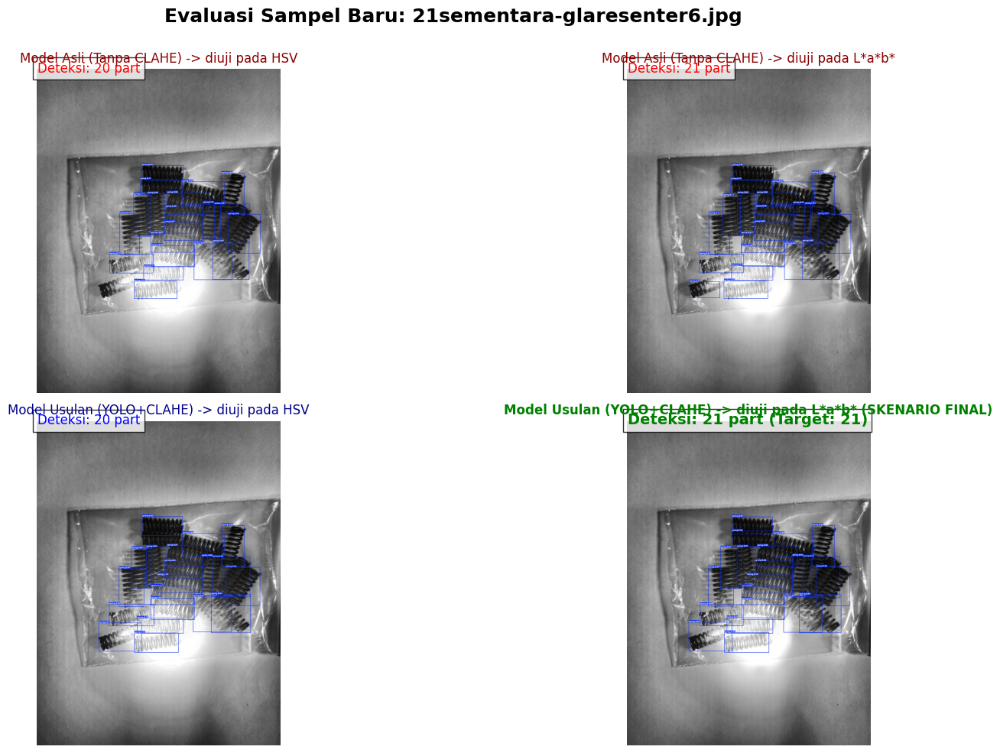

In [ ]:
import os
import shutil
import cv2
import matplotlib.pyplot as plt
import numpy as np

# =========================================================================
# 1. BERSIHKAN SEMUANYA
# =========================================================================
print("🧹 Membersihkan seluruh folder hasil lama...")
folders_to_delete = ['detect_S1_HSV_new', 'detect_S1_LAB_new', 'detect_S2_HSV_new', 'detect_S2_LAB_new']
for folder in folders_to_delete:
    shutil.rmtree(f'/content/yolov5/runs/detect/{folder}', ignore_errors=True)
shutil.rmtree('/content/test_hsv_new', ignore_errors=True)
shutil.rmtree('/content/test_lab_new', ignore_errors=True)

# =========================================================================
# 2. PRAPEMROSESAN (DENGAN PENAMAAN FILE YANG AMAN)
# =========================================================================
print("\n📥 Menyiapkan Citra Uji Baru...")
os.makedirs('/content/test_hsv_new', exist_ok=True)
os.makedirs('/content/test_lab_new', exist_ok=True)

all_images = [
    '21sementara-normal.jpg', '21sementara-glaresenter.jpg', '21sementara-glarelampuhp1.jpg', '21sementara-glarelampuhp2.jpg',
    '21sementara-glarelampuhp3.jpg', '21sementara-glarelampuhp4.jpg', '21sementara-glarelampuhp5.jpg', '21sementara-glarelampuhp6.jpg', '21sementara-glarelampuhp7.jpg',
    '21sementara-glaresenter2.jpg', '21sementara-glaresenter3.jpg', '21sementara-glaresenter4.jpg', '21sementara-glaresenter5.jpg', '21sementara-glaresenter6.jpg'
]

print("🔄 Konversi HSV dan LAB (Mengubah nama file untuk mencegah bentrok)...")
for img_name in all_images:
    img_path = f'/content/test_images_new/{img_name}'
    if not os.path.exists(img_path): continue

    img_bgr = cv2.imread(img_path)
    if img_bgr is not None:
        # HSV -> Simpan dengan prefix hsv_
        img_hsv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)
        h, s, v = cv2.split(img_hsv)
        v_clahe = cv2.createCLAHE(clipLimit=3.0, tileGridSize=(4, 4)).apply(v)
        cv2.imwrite(f'/content/test_hsv_new/hsv_{img_name}', cv2.merge((v_clahe, v_clahe, v_clahe)))

        # LAB -> Simpan dengan prefix lab_
        img_lab = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB)
        l, a, b = cv2.split(img_lab)
        l_clahe = cv2.createCLAHE(clipLimit=3.0, tileGridSize=(4, 4)).apply(l)
        cv2.imwrite(f'/content/test_lab_new/lab_{img_name}', cv2.merge((l_clahe, l_clahe, l_clahe)))

# =========================================================================
# 3. DETEKSI
# =========================================================================
os.chdir('/content/yolov5')
print("\n🚀 Memulai Pengujian 4 Arah...")

# S1
os.system("python detect.py --weights /content/yolov5/runs/train/YOLOv5s_Original_PeerSpring4/weights/best.pt --img 640 --conf 0.50 --source /content/test_hsv_new/ --name detect_S1_HSV_new --save-txt")
os.system("python detect.py --weights /content/yolov5/runs/train/YOLOv5s_Original_PeerSpring4/weights/best.pt --img 640 --conf 0.50 --source /content/test_lab_new/ --name detect_S1_LAB_new --save-txt")

# S2
os.system("python detect.py --weights /content/best_S2_CLAHE.pt --img 640 --conf 0.50 --source /content/test_hsv_new/ --name detect_S2_HSV_new --save-txt")
os.system("python detect.py --weights /content/best_S2_CLAHE.pt --img 640 --conf 0.50 --source /content/test_lab_new/ --name detect_S2_LAB_new --save-txt")

# =========================================================================
# 4. VISUALISASI MATRIKS 2x2
# =========================================================================
print("\n🔍 VISUALISASI HASIL\n")

def get_count(txt_path):
    if os.path.exists(txt_path):
        with open(txt_path, 'r') as f:
            return len(f.readlines())
    return 0

def load_img(img_path):
    if os.path.exists(img_path):
        return cv2.cvtColor(cv2.imread(img_path), cv2.COLOR_BGR2RGB)
    return np.zeros((640,640,3), dtype=np.uint8)

for img_name in all_images:
    plt.figure(figsize=(20, 10))
    plt.suptitle(f"Evaluasi Sampel Baru: {img_name}", fontsize=18, fontweight='bold')

    hsv_name = f'hsv_{img_name}'
    lab_name = f'lab_{img_name}'

    # Path Folder Hasil
    p_S1_HSV = f'/content/yolov5/runs/detect/detect_S1_HSV_new/{hsv_name}'
    p_S1_LAB = f'/content/yolov5/runs/detect/detect_S1_LAB_new/{lab_name}'
    p_S2_HSV = f'/content/yolov5/runs/detect/detect_S2_HSV_new/{hsv_name}'
    p_S2_LAB = f'/content/yolov5/runs/detect/detect_S2_LAB_new/{lab_name}'

    # Path Teks Hitungan
    t_S1_HSV = f'/content/yolov5/runs/detect/detect_S1_HSV_new/labels/{hsv_name.replace(".jpg", ".txt")}'
    t_S1_LAB = f'/content/yolov5/runs/detect/detect_S1_LAB_new/labels/{lab_name.replace(".jpg", ".txt")}'
    t_S2_HSV = f'/content/yolov5/runs/detect/detect_S2_HSV_new/labels/{hsv_name.replace(".jpg", ".txt")}'
    t_S2_LAB = f'/content/yolov5/runs/detect/detect_S2_LAB_new/labels/{lab_name.replace(".jpg", ".txt")}'

    # Plot 1: S1 HSV
    plt.subplot(2, 2, 1)
    plt.title("Model Asli (Tanpa CLAHE) -> diuji pada HSV", fontsize=12, color='darkred')
    plt.imshow(load_img(p_S1_HSV))
    plt.axis('off')
    plt.text(10, 50, f'Deteksi: {get_count(t_S1_HSV)} part', color='red', fontsize=12, bbox=dict(facecolor='white', alpha=0.8))

    # Plot 2: S1 LAB
    plt.subplot(2, 2, 2)
    plt.title("Model Asli (Tanpa CLAHE) -> diuji pada L*a*b*", fontsize=12, color='darkred')
    plt.imshow(load_img(p_S1_LAB))
    plt.axis('off')
    plt.text(10, 50, f'Deteksi: {get_count(t_S1_LAB)} part', color='red', fontsize=12, bbox=dict(facecolor='white', alpha=0.8))

    # Plot 3: S2 HSV
    plt.subplot(2, 2, 3)
    plt.title("Model Usulan (YOLO+CLAHE) -> diuji pada HSV", fontsize=12, color='darkblue')
    plt.imshow(load_img(p_S2_HSV))
    plt.axis('off')
    plt.text(10, 50, f'Deteksi: {get_count(t_S2_HSV)} part', color='blue', fontsize=12, bbox=dict(facecolor='white', alpha=0.8))

    # Plot 4: S2 LAB
    plt.subplot(2, 2, 4)
    plt.title("Model Usulan (YOLO+CLAHE) -> diuji pada L*a*b* (SKENARIO FINAL)", fontsize=12, fontweight='bold', color='green')
    plt.imshow(load_img(p_S2_LAB))
    plt.axis('off')
    plt.text(10, 50, f'Deteksi: {get_count(t_S2_LAB)} part (Target: 21)', color='green', fontsize=14, fontweight='bold', bbox=dict(facecolor='white', alpha=0.8))

    plt.tight_layout()
    plt.subplots_adjust(top=0.9)
    plt.show()

## Komparasi Citra Asli vs HSV vs L* a* b* - Tanpa Bounding Box

🔍 ANALISIS VISUAL PRAPEMROSESAN (ASLI vs HSV vs L*a*b*)



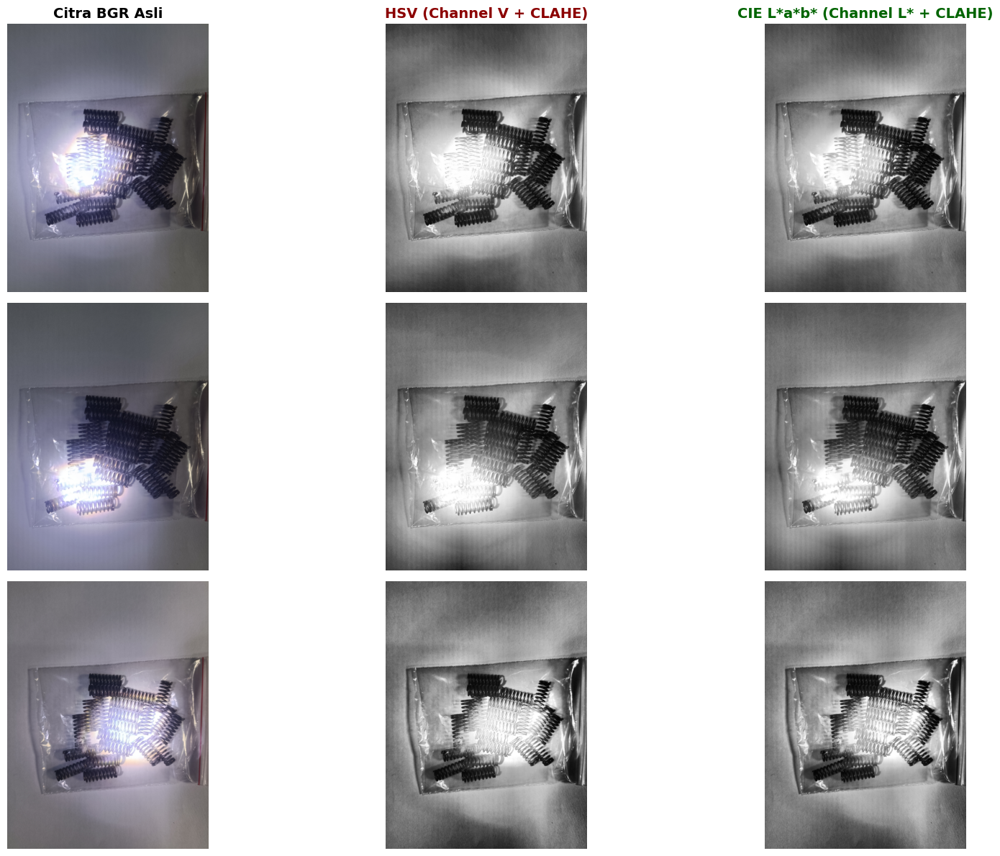

In [ ]:
import cv2
import matplotlib.pyplot as plt
import os

print("🔍 ANALISIS VISUAL PRAPEMROSESAN (ASLI vs HSV vs L*a*b*)\n")

# Pilih beberapa sampel representatif (misal 3 gambar senter)
sample_to_view = ['21sementara-glaresenter3.jpg', '21sementara-glaresenter4.jpg', '21sementara-glaresenter5.jpg']

plt.figure(figsize=(18, 12))

for i, img_name in enumerate(sample_to_view):
    # Path gambar
    path_bgr = f'/content/test_images_new/{img_name}'
    path_hsv = f'/content/test_hsv_new/hsv_{img_name}'
    path_lab = f'/content/test_lab_new/lab_{img_name}'

    # Load gambar
    img_bgr = cv2.cvtColor(cv2.imread(path_bgr), cv2.COLOR_BGR2RGB) if os.path.exists(path_bgr) else None
    img_hsv = cv2.cvtColor(cv2.imread(path_hsv), cv2.COLOR_BGR2RGB) if os.path.exists(path_hsv) else None
    img_lab = cv2.cvtColor(cv2.imread(path_lab), cv2.COLOR_BGR2RGB) if os.path.exists(path_lab) else None

    # Plot Asli (Kiri)
    plt.subplot(3, 3, i*3 + 1)
    if i == 0: plt.title("Citra BGR Asli", fontsize=14, fontweight='bold')
    plt.imshow(img_bgr)
    plt.axis('off')

    # Plot HSV (Tengah)
    plt.subplot(3, 3, i*3 + 2)
    if i == 0: plt.title("HSV (Channel V + CLAHE)", fontsize=14, fontweight='bold', color='darkred')
    plt.imshow(img_hsv)
    plt.axis('off')

    # Plot LAB (Kanan) - SKENARIO FINAL
    plt.subplot(3, 3, i*3 + 3)
    if i == 0: plt.title("CIE L*a*b* (Channel L* + CLAHE)", fontsize=14, fontweight='bold', color='darkgreen')
    plt.imshow(img_lab)
    plt.axis('off')

plt.tight_layout()
plt.show()

## Komparasi Final | Hasil Deteksi YOLOv5s Original vs YOLOv5s + CLAHE (pada HSV) vs YOLOv5s + CLAHE (pada L* a* b*)

🚀 Menjalankan Deteksi Model Asli pada Citra BGR Original (Baseline)...

🔍 MENAMPILKAN VISUALISASI FINAL DENGAN GAMBAR ORIGINAL + BOUNDING BOX



KONDISI 1: NORMAL (Top-View, No Glare)



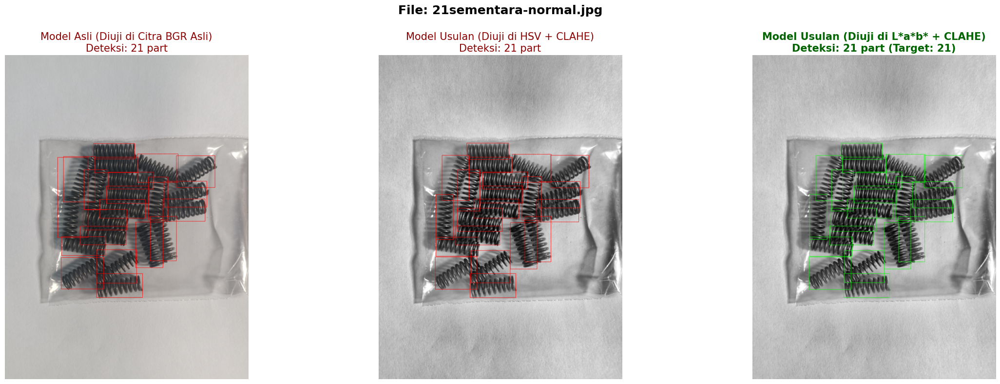



KONDISI 2: GLARE LAMPU HP (Pantulan Menyebar / Diffuse)



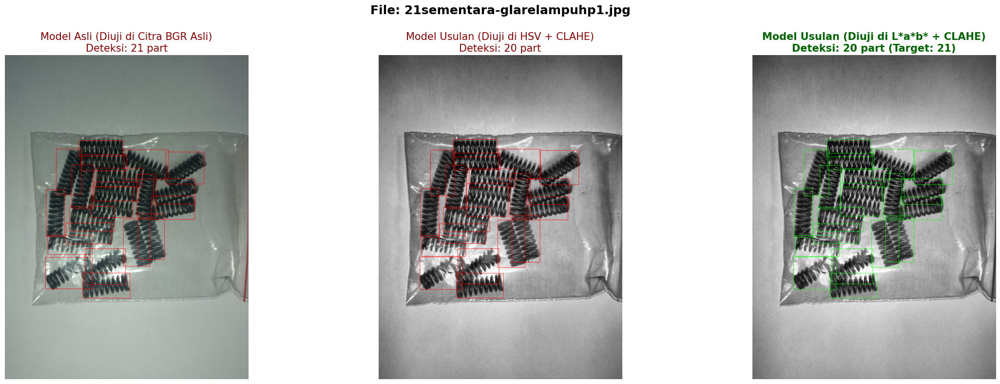

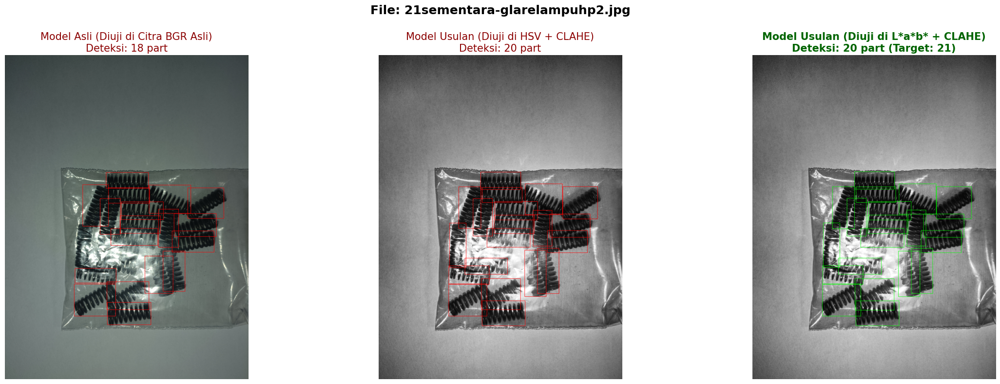

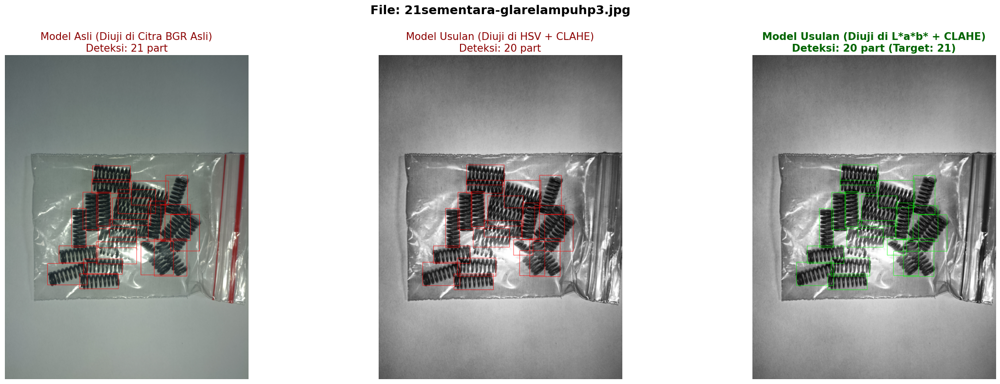

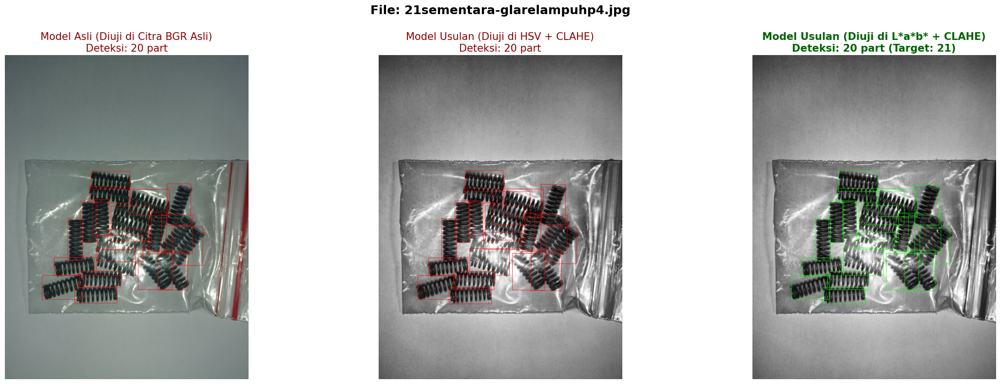

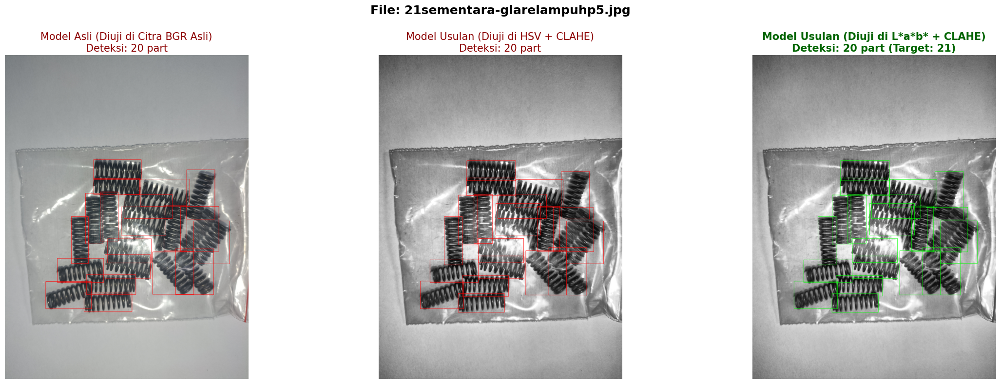

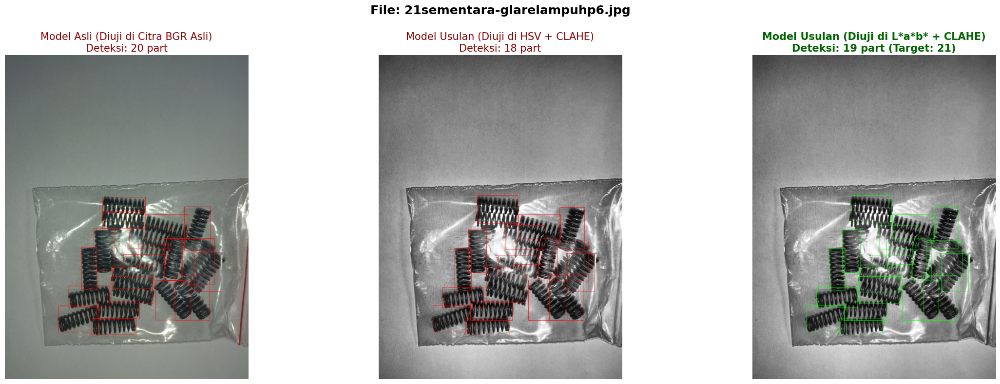

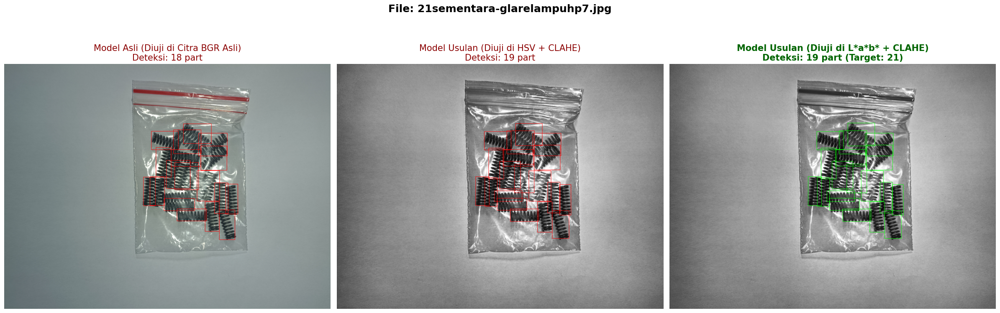



KONDISI 3: GLARE SENTER (Pantulan Terpusat Ekstrem)



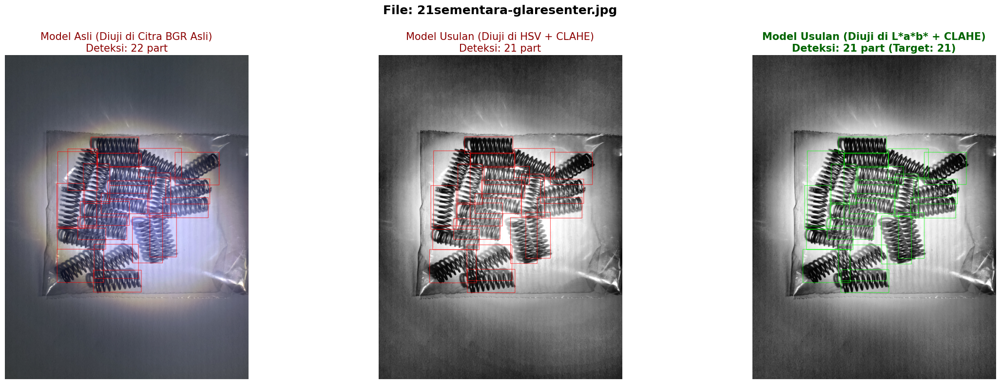

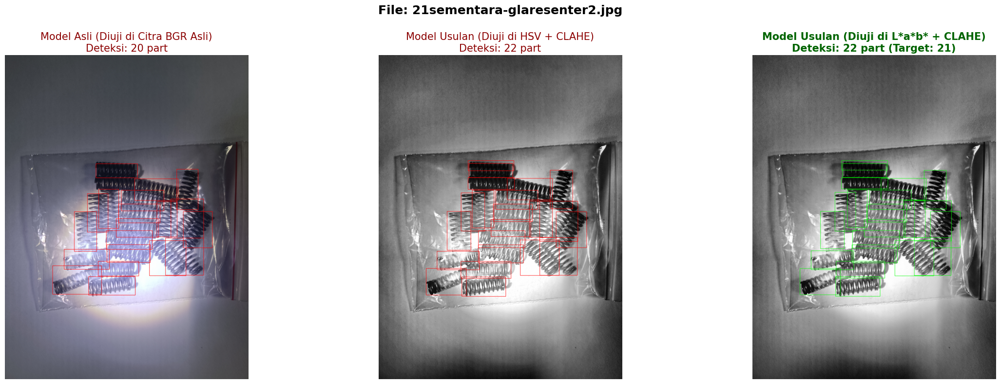

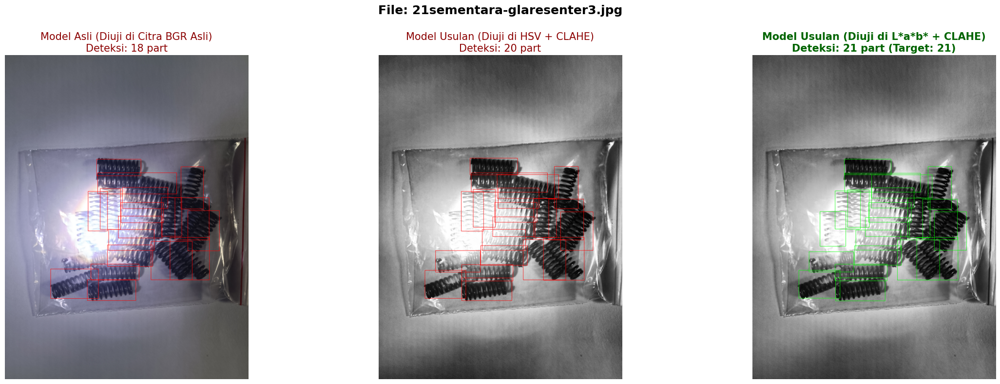

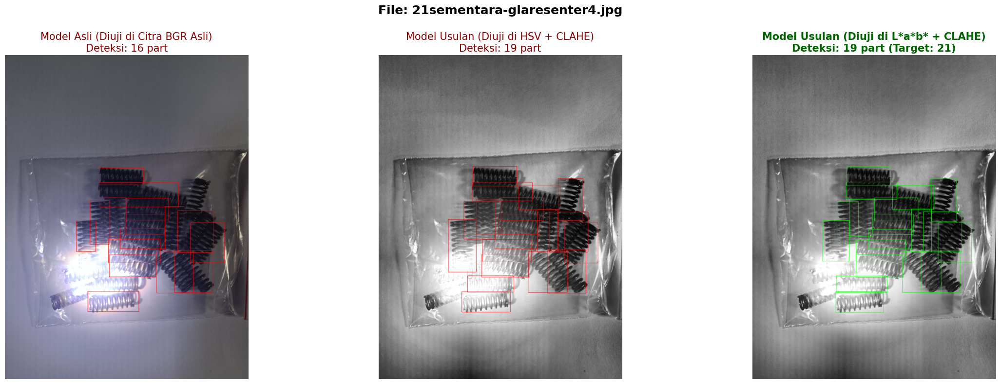

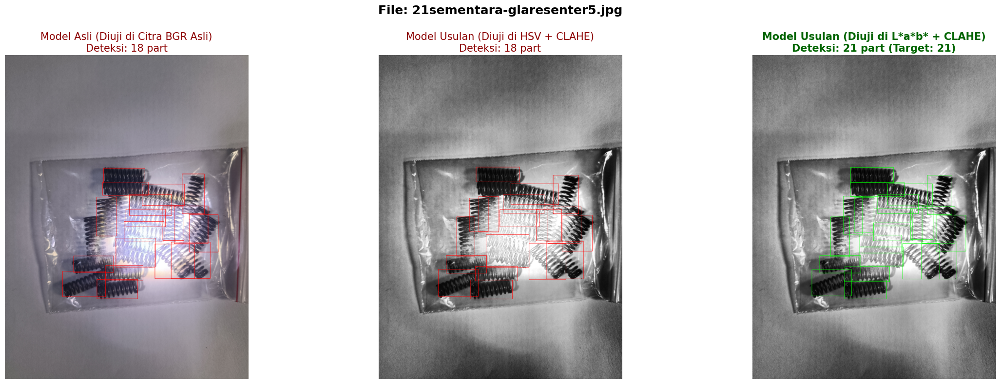

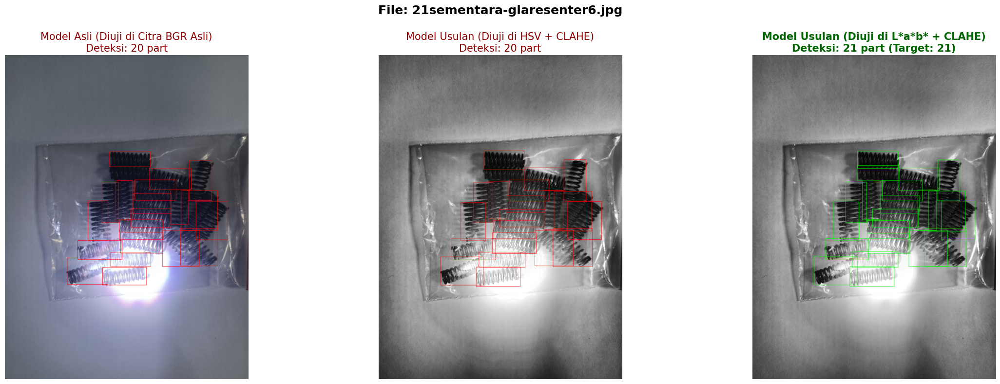

In [ ]:
import os
import cv2
import matplotlib.pyplot as plt
import numpy as np

# 1. RUN BASELINE DETECTION (Jika belum ada)
# Kita butuh deteksi Model Asli pada gambar BGR Asli untuk kolom pertama
print("🚀 Menjalankan Deteksi Model Asli pada Citra BGR Original (Baseline)...")
os.system("python /content/yolov5/detect.py --weights /content/yolov5/runs/train/YOLOv5s_Original_PeerSpring4/weights/best.pt --img 640 --conf 0.50 --source /content/test_images_new/ --name detect_S1_ORI_new --save-txt --exist-ok")

# 2. DEFINISI FUNGSI CUSTOM GAMBAR BOX
def draw_yolo_boxes(img_path, txt_path, box_color):
    """Fungsi untuk menggambar kotak langsung di atas gambar MENTAH agar teksturnya tidak hilang"""
    img = cv2.imread(img_path)
    if img is None:
        return np.zeros((640,640,3), dtype=np.uint8), 0

    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    count = 0

    if os.path.exists(txt_path):
        with open(txt_path, 'r') as f:
            lines = f.readlines()
            count = len(lines)
            h, w, _ = img.shape
            for line in lines:
                parts = line.strip().split()
                if len(parts) == 5:
                    x_center, y_center, width, height = map(float, parts[1:])
                    # Konversi format YOLO ke koordinat piksel OpenCV
                    x1 = int((x_center - width/2) * w)
                    y1 = int((y_center - height/2) * h)
                    x2 = int((x_center + width/2) * w)
                    y2 = int((y_center + height/2) * h)
                    # Gambar kotak (ketebalan 4 piksel)
                    cv2.rectangle(img, (x1, y1), (x2, y2), box_color, 4)
    return img, count

# 3. KELOMPOKKAN GAMBAR (NORMAL, HP, SENTER)
groups = {
    "KONDISI 1: NORMAL (Top-View, No Glare)": ['21sementara-normal.jpg'],

    "KONDISI 2: GLARE LAMPU HP (Pantulan Menyebar / Diffuse)": [
        '21sementara-glarelampuhp1.jpg', '21sementara-glarelampuhp2.jpg',
        '21sementara-glarelampuhp3.jpg', '21sementara-glarelampuhp4.jpg',
        '21sementara-glarelampuhp5.jpg', '21sementara-glarelampuhp6.jpg',
        '21sementara-glarelampuhp7.jpg'
    ],

    "KONDISI 3: GLARE SENTER (Pantulan Terpusat Ekstrem)": [
        '21sementara-glaresenter.jpg', '21sementara-glaresenter2.jpg',
        '21sementara-glaresenter3.jpg', '21sementara-glaresenter4.jpg',
        '21sementara-glaresenter5.jpg', '21sementara-glaresenter6.jpg'
    ]
}

print("\n🔍 MENAMPILKAN VISUALISASI FINAL DENGAN GAMBAR ORIGINAL + BOUNDING BOX\n")

for group_name, images in groups.items():
    # Beri pemisah teks tebal antar kondisi
    print(f"\n\n{'='*100}")
    print(f"{group_name}")
    print(f"{'='*100}\n")

    for img_name in images:
        plt.figure(figsize=(24, 8))

        # Paths Images (Gambar Mentah)
        p_ori = f'/content/test_images_new/{img_name}'
        p_hsv = f'/content/test_hsv_new/hsv_{img_name}'
        p_lab = f'/content/test_lab_new/lab_{img_name}'

        # Paths Labels (Koordinat TXT dari YOLO)
        t_ori = f'/content/yolov5/runs/detect/detect_S1_ORI_new/labels/{img_name.replace(".jpg", ".txt")}'
        t_hsv = f'/content/yolov5/runs/detect/detect_S2_HSV_new/labels/hsv_{img_name.replace(".jpg", ".txt")}'
        t_lab = f'/content/yolov5/runs/detect/detect_S2_LAB_new/labels/lab_{img_name.replace(".jpg", ".txt")}'

        # Eksekusi fungsi gambar kotak
        img_ori_box, c_ori = draw_yolo_boxes(p_ori, t_ori, box_color=(255, 0, 0))   # Kotak Merah
        img_hsv_box, c_hsv = draw_yolo_boxes(p_hsv, t_hsv, box_color=(255, 0, 0))   # Kotak Merah
        img_lab_box, c_lab = draw_yolo_boxes(p_lab, t_lab, box_color=(0, 255, 0))   # Kotak Hijau

        # --- KOLOM 1: Model Asli ---
        plt.subplot(1, 3, 1)
        plt.title(f"Model Asli (Diuji di Citra BGR Asli)\nDeteksi: {c_ori} part", fontsize=15, color='darkred')
        plt.imshow(img_ori_box)
        plt.axis('off')

        # --- KOLOM 2: Model Usulan (HSV) ---
        plt.subplot(1, 3, 2)
        plt.title(f"Model Usulan (Diuji di HSV + CLAHE)\nDeteksi: {c_hsv} part", fontsize=15, color='darkred')
        plt.imshow(img_hsv_box)
        plt.axis('off')

        # --- KOLOM 3: Model Usulan (L*a*b*) - SKENARIO FINAL ---
        plt.subplot(1, 3, 3)
        plt.title(f"Model Usulan (Diuji di L*a*b* + CLAHE)\nDeteksi: {c_lab} part (Target: 21)", fontsize=15, fontweight='bold', color='darkgreen')
        plt.imshow(img_lab_box)
        plt.axis('off')

        plt.suptitle(f"File: {img_name}", fontsize=18, fontweight='bold')
        plt.tight_layout()
        plt.subplots_adjust(top=0.85)
        plt.show()

# Revisi / Penyempurnaan

### Mitigasi Kebocoran Data (Test-Set Leakage Prevention)
Merujuk pada kaidah validitas *Machine Learning*, pengujian *Grid Search* pada notebook ini **TIDAK menggunakan 14 citra uji statis (*Testing Set*)**. Sebagai gantinya, sistem secara otomatis mengambil sampel 10 citra dari **Himpunan Latih/Validasi Roboflow (*Calibration Set*)**. Pendekatan ini menjamin bahwa 14 citra uji ekstrem tetap berstatus murni sebagai *unseen data* yang belum pernah dilihat model untuk evaluasi akhir skripsi.

In [ ]:
# 1. Kloning Repositori YOLOv5 dan Instalasi Dependensi
import os

print("⚙️ Mengunduh repositori YOLOv5 dan menginstal dependensi...")
!git clone https://github.com/ultralytics/yolov5
%cd /content/yolov5
!pip install -qr requirements.txt
!pip install -q roboflow

import torch
import cv2
import glob
import random
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print(f"✅ Setup selesai! PyTorch versi: {torch.__version__} | CUDA Tersedia: {torch.cuda.is_available()}")

⚙️ Mengunduh repositori YOLOv5 dan menginstal dependensi...
Cloning into 'yolov5'...
remote: Enumerating objects: 18756, done.
remote: Counting objects: 100% (319/319), done.
remote: Compressing objects: 100% (185/185), done.
remote: Total 18756 (delta 263), reused 134 (delta 134), pack-reused 18437 (from 4)
Receiving objects: 100% (18756/18756), 17.79 MiB | 18.44 MiB/s, done.
Resolving deltas: 100% (12762/12762), done.
/content/yolov5
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.7/46.7 kB 1.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 74.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 78.4/78.4 kB 8.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 322.4/322.4 kB 27.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 73.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 6.2 MB/s eta 0:00:00
✅ Setup selesai! PyTorch versi: 2.11.0+cu128 | CUDA Tersedia: True


## 1. Menyiapkan Berkas Bobot Model (best.pt)
Unggah berkas bobot model terbaik hasil pelatihan (`best.pt`)

In [ ]:
from google.colab import files

print("📤 Silakan pilih dan unggah file 'best.pt' Anda:")
uploaded = files.upload()

# Verifikasi lokasi file best.pt
if 'best.pt' in uploaded:
    !mv /content/yolov5/best.pt /content/best.pt 2>/dev/null || true
    MODEL_PATH = '/content/best.pt'
    print(f"\n✅ Berkas bobot berhasil diunggah pada: {MODEL_PATH}")
else:
    # Mengambil nama file jika namanya bukan best.pt
    filename = list(uploaded.keys())[0]
    MODEL_PATH = f'/content/{filename}'
    print(f"\n✅ Berkas bobot terdeteksi: {MODEL_PATH}")

📤 Silakan pilih dan unggah file 'best.pt' Anda:


Saving best.pt to best.pt

✅ Berkas bobot berhasil diunggah pada: /content/best.pt


## 2. Mengunduh Dataset Asli via API Roboflow
Sistem menarik dataset asli langsung dari repositori Roboflow peneliti guna mengambil sampel data kalibrasi secara otomatis tanpa perlu unggah manual.

In [ ]:
from roboflow import Roboflow

print("📥 Mengunduh Dataset Citra dari Roboflow...")

# Otentikasi API Roboflow
rf = Roboflow(api_key="mqzu0AtL172Rw5BZNWr3")
project = rf.workspace("nadhifs-workspace").project("datasetskripsi-g9pqj")
dataset = project.version(1).download("yolov5")

# Simpan lokasi dataset
DATASET_DIR = dataset.location
print(f"\n✅ Dataset berhasil diunduh ke: {DATASET_DIR}")

📥 Mengunduh Dataset Citra dari Roboflow...
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to DatasetSkripsi-1 in yolov5pytorch:: 100%|██████████| 607/607 [00:00<00:00, 3227.21it/s]



✅ Dataset berhasil diunduh ke: /content/yolov5/DatasetSkripsi-1


## 3. Eksekusi Grid Search pada 10 Citra Kalibrasi
Pada tahap ini, sistem secara otomatis mengambil sampel acak 10 citra dari folder `train/images/` (*Calibration Set*).

Kombinasi parameter yang dievaluasi mencakup:
*   **Clip Limit:** [2.0, 3.0, 4.0]
*   **Tile Grid Size:** [(4, 4), (8, 8), (16, 16)] (didefinisikan sebagai jumlah pembagian partisi *grid tiles*)

**Aturan Pemecah Seri (*Tie-Breaker Rule*):**
Apabila terdapat dua atau lebih konfigurasi parameter yang menghasilkan nilai rata-rata kesalahan (*Mean Absolute Error*) yang identik, maka parameter dengan **Clip Limit yang lebih rendah** akan dipilih guna memitigasi risiko penguatan derau artifisial (*over-enhancement*).

🧠 Memuat model YOLOv5...
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
YOLOv5 🚀 v7.0-553-g402e17dd Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)

Fusing layers... 
Model summary: 68 layers, 7,012,822 parameters, 0 gradients, 15.8 GFLOPs
Adding AutoShape... 
✅ Berhasil memilih 10 citra kalibrasi dari total 302 data latih.

⏳ Menjalankan iterasi Grid Search CLAHE...

🏆 HASIL KALIBRASI GRID SEARCH (Diurutkan dari Error Terkecil):
 Clip Limit Grid Size  Avg Error (Selisih)
        3.0       4x4                  3.0
        3.0     16x16                  3.0
        4.0       4x4                  3.1
        2.0       4x4                  3.1
        4.0       8x8                  3.1
        4.0     16x16                  3.1
     

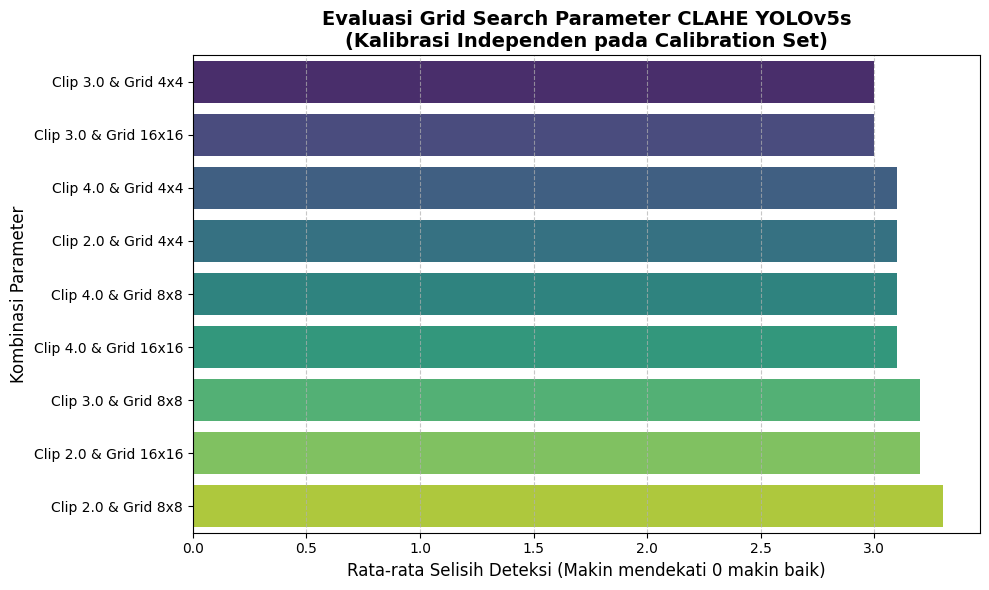


✅ Grafik evaluasi berhasil disimpan ke: /content/Grid_Search_CLAHE_Calibration.png


In [ ]:
# 1. Load Model YOLOv5
print("🧠 Memuat model YOLOv5...")
model = torch.hub.load('/content/yolov5', 'custom', path=MODEL_PATH, source='local')
model.conf = 0.50 # Sesuai standar confidence threshold pengujian gambar statis

# 2. Ambil 10 Gambar Sampel dari Folder Train (Bukan dari Testing Set)
train_images_all = glob.glob(f"{DATASET_DIR}/train/images/*.jpg")

# Gunakan seed agar 10 gambar yang terpilih selalu konsisten/reproducible
random.seed(42)
calibration_images = random.sample(train_images_all, min(10, len(train_images_all)))

print(f"✅ Berhasil memilih {len(calibration_images)} citra kalibrasi dari total {len(train_images_all)} data latih.")

# 3. Setup Parameter Grid Search
TARGET_COUNT = 21 # Target kuantitas ground truth objek
clip_limits = [2.0, 3.0, 4.0]
grid_sizes = [(4, 4), (8, 8), (16, 16)]
results = []

print("\n⏳ Menjalankan iterasi Grid Search CLAHE...")

for clip in clip_limits:
    for grid in grid_sizes:
        total_error = 0
        for img_path in calibration_images:
            img_bgr = cv2.imread(img_path)
            if img_bgr is None: continue

            # Ekstraksi saluran L* dan penerapan CLAHE
            img_lab = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB)
            l, a, b = cv2.split(img_lab)
            clahe = cv2.createCLAHE(clipLimit=clip, tileGridSize=grid)
            l_clahe = clahe.apply(l)
            img_clahe = cv2.merge((l_clahe, l_clahe, l_clahe))

            # Inferensi Model
            pred = model(img_clahe)
            detected_count = len(pred.xyxy[0])

            # Kalkulasi selisih absolut terhadap ground truth
            total_error += abs(TARGET_COUNT - detected_count)

        avg_error = total_error / len(calibration_images)
        results.append({
            'Clip Limit': clip,
            'Grid Size': f"{grid[0]}x{grid[1]}",
            'Avg Error (Selisih)': avg_error
        })

# 4. Tampilkan Hasil Tabel Numerik
df_results = pd.DataFrame(results)
print("\n🏆 HASIL KALIBRASI GRID SEARCH (Diurutkan dari Error Terkecil):")
df_sorted = df_results.sort_values('Avg Error (Selisih)')
print(df_sorted.to_string(index=False))

# 5. Visualisasi Grafik Bar Chart (Resolusi Tinggi 300 DPI)
df_results['Kombinasi'] = 'Clip ' + df_results['Clip Limit'].astype(str) + ' & Grid ' + df_results['Grid Size']
df_sorted_plot = df_results.sort_values('Avg Error (Selisih)')

plt.figure(figsize=(10, 6))
# Penyesuaian sintaks Seaborn terbaru untuk mencegah deprecation warning
sns.barplot(
    data=df_sorted_plot,
    x='Avg Error (Selisih)',
    y='Kombinasi',
    palette='viridis',
    hue='Kombinasi',
    legend=False
)

plt.title('Evaluasi Grid Search Parameter CLAHE YOLOv5s\n(Kalibrasi Independen pada Calibration Set)', fontsize=14, fontweight='bold')
plt.xlabel('Rata-rata Selisih Deteksi (Makin mendekati 0 makin baik)', fontsize=12)
plt.ylabel('Kombinasi Parameter', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.7)

plt.tight_layout()
output_chart = '/content/Grid_Search_CLAHE_Calibration.png'
plt.savefig(output_chart, dpi=300)
plt.show()

print(f"\n✅ Grafik evaluasi berhasil disimpan ke: {output_chart}")

## 4. Mengunduh Berkas Grafik Hasil Kalibrasi
Jalankan sel di bawah untuk langsung mengunduh gambar grafik `.png` beresolusi tinggi ke laptop Anda.

In [ ]:
from google.colab import files
files.download('/content/Grid_Search_CLAHE_Calibration.png')
print("📥 Mengunduh grafik...")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

📥 Mengunduh grafik...
